# Treinamento e Avaliacao — Deteccao de Anomalias em Sensores Forzy

**Sprint 3** | Isolation Forest (nao supervisionado) + Autoencoder (semissupervisionado)

Este notebook treina e avalia dois modelos complementares de deteccao de
anomalias sobre o historico real de sensores da Forzy, usando o baseline
operacional definido no notebook anterior como referencia.

**Abordagem declarada:** este projeto **nao possui rotulos de falha** — nenhuma
leitura do `forzy_history.csv` indica se corresponde a uma condicao normal ou
anomala. Por isso, dois paradigmas complementares sao adotados:

- **Isolation Forest — nao supervisionado.** Treinado sobre todo o historico
  sem qualquer suposicao sobre quais leituras sao normais, isola pontos raros
  no espaco de features.
- **Autoencoder — semissupervisionado.** Treinado apenas sobre um subconjunto
  presumivelmente normal (os 5 ciclos operacionais mais curtos e o repouso),
  deixando o Ciclo 6 (candidato a anomalia identificado na EDA) fora do
  treinamento para testar se o modelo o reconhece como divergente do padrao
  aprendido.

**Sumario:**
1. Carregamento dos Dados e do Baseline
2. Preparacao dos Dados e Feature Engineering
3. Modelo 1 — Isolation Forest (nao supervisionado)
4. Modelo 2 — Autoencoder (semissupervisionado)
5. Comparacao entre os Modelos
6. Avaliacao sem Rotulos — Validacao Cruzada de Metodos
7. Analise dos Casos Anomalos
8. Visualizacao dos Resultados
9. Serializacao dos Modelos


In [1]:
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score

import torch
import torch.nn as nn

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11})
torch.manual_seed(42)
np.random.seed(42)

print("Pacotes carregados. Torch:", torch.__version__)


Pacotes carregados. Torch: 2.13.0+cu130


## 1. Carregamento dos Dados e do Baseline

In [2]:
df = pd.read_csv('forzy_history.csv', sep=';', skiprows=3, header=None, encoding='utf-8')
df.columns = [
    'timestamp', 'port1_raw', 'port2_raw',
    'p1_velocidade', 'p1_aceleracao', 'p1_temperatura',
    'p2_velocidade', 'p2_aceleracao', 'p2_temperatura'
]
df = df.drop(columns=['port1_raw', 'port2_raw'])
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.sort_values('timestamp').reset_index(drop=True)

SENSOR_COLS = ['p1_velocidade', 'p1_aceleracao', 'p1_temperatura',
               'p2_velocidade', 'p2_aceleracao', 'p2_temperatura']

with open('baseline_operacional.json') as f:
    baseline = json.load(f)

print(f"Shape: {df.shape}")
print(f"Baseline operacional carregado: estados {list(baseline.keys())}")


Shape: (7183, 7)
Baseline operacional carregado: estados ['idle', 'running', 'cross_port', 'ciclo_tipico']


## 2. Preparacao dos Dados e Feature Engineering

### 2.1 Tratamento de Valores Ausentes e Ruido
Como verificado na EDA, nao ha valores nulos no dataset. O ruido de fundo do
sensor (leituras de repouso na faixa 0,03-0,10 mm/s) e preservado — ele define
o piso de operacao normal e nao deve ser filtrado.

### 2.2 Amostragem Irregular
A amostragem *report-on-change* do IO-Link produz intervalos de tempo variaveis
entre leituras. Em vez de reamostrar para uma grade fixa (o que exigiria
interpolar sobre longos periodos de repouso e poderia mascarar transicoes),
mantemos a granularidade original por leitura e incluimos o **intervalo de
tempo desde a leitura anterior** (`dt_seg`) como feature explicita — ele
proprio carrega informacao (leituras raras/dt grande tendem a ocorrer em
repouso estavel; leituras frequentes/dt pequeno ocorrem durante transientes).

### 2.3 Janelas Moveis e Consistencia Cruzada
Features de janela movel (media e desvio padrao das ultimas 5 leituras) capturam
tendencia local. Features de diferenca entre portas capturam a consistencia
cruzada identificada como parte do baseline operacional.


**Achado de qualidade de dados:** o log do IO-Link Master ocasionalmente
registra duas leituras quase simultaneas (intervalo de ~0,001s), provavelmente
por duplicidade de evento no proprio dispositivo de aquisicao. Ao calcular
features de taxa de variacao (delta de sensor dividido pelo tempo decorrido),
esses casos gerariam valores espurios extremos por divisao por um numero muito
pequeno. A secao de feature engineering aplica um piso minimo de 0,1s
exclusivamente no denominador dessas features para neutralizar esse artefato,
sem descartar as leituras (que permanecem validas para as demais features).

In [3]:
WINDOW = 5

# Estado operacional (repouso / operacao) — mesmo limiar definido na EDA
THRESH_RUNNING = 0.5
df['running'] = ((df['p1_velocidade'] > THRESH_RUNNING) |
                  (df['p2_velocidade'] > THRESH_RUNNING)).astype(int)
df['cycle_id'] = (df['running'] != df['running'].shift()).cumsum()

# Intervalo de tempo entre leituras (feature explicita da amostragem irregular)
df['dt_seg'] = df['timestamp'].diff().dt.total_seconds().fillna(0).clip(upper=60)

# Nota de qualidade de dados: o log do IO-Link Master ocasionalmente registra
# leituras com intervalo quase nulo (dt_seg proximo de 0.001s), provavelmente
# por duplicidade de evento no proprio dispositivo de aquisicao. Ao calcular a
# taxa de variacao (delta/dt), esses casos gerariam valores espurios extremos
# por divisao por um numero muito pequeno. Por isso, aplicamos um piso minimo
# de 0.1s exclusivamente no denominador da taxa, preservando o dt_seg original
# (sem piso) como feature independente de frequencia de amostragem.
dt_seg_piso = df['dt_seg'].clip(lower=0.1)

# Features de janela movel por sensor
for col in SENSOR_COLS:
    df[f'{col}_mean5'] = df[col].rolling(WINDOW, min_periods=1).mean()
    df[f'{col}_std5']  = df[col].rolling(WINDOW, min_periods=1).std().fillna(0)

# Taxa de variacao (derivada aproximada, normalizada pelo tempo decorrido com piso)
for col in SENSOR_COLS:
    delta = df[col].diff().fillna(0)
    df[f'{col}_taxa'] = (delta / dt_seg_piso).clip(-50, 50)

# Consistencia cruzada entre portas
df['diff_vel']  = df['p1_velocidade'] - df['p2_velocidade']
df['diff_temp'] = df['p1_temperatura'] - df['p2_temperatura']
df['diff_acel'] = df['p1_aceleracao'] - df['p2_aceleracao']

FEATURE_COLS = (SENSOR_COLS
                + [f'{c}_mean5' for c in SENSOR_COLS]
                + [f'{c}_std5'  for c in SENSOR_COLS]
                + [f'{c}_taxa'  for c in SENSOR_COLS]
                + ['diff_vel', 'diff_temp', 'diff_acel', 'running', 'dt_seg'])

print(f"Total de features: {len(FEATURE_COLS)}")
for f in FEATURE_COLS:
    print(f"  - {f}")


Total de features: 29
  - p1_velocidade
  - p1_aceleracao
  - p1_temperatura
  - p2_velocidade
  - p2_aceleracao
  - p2_temperatura
  - p1_velocidade_mean5
  - p1_aceleracao_mean5
  - p1_temperatura_mean5
  - p2_velocidade_mean5
  - p2_aceleracao_mean5
  - p2_temperatura_mean5
  - p1_velocidade_std5
  - p1_aceleracao_std5
  - p1_temperatura_std5
  - p2_velocidade_std5
  - p2_aceleracao_std5
  - p2_temperatura_std5
  - p1_velocidade_taxa
  - p1_aceleracao_taxa
  - p1_temperatura_taxa
  - p2_velocidade_taxa
  - p2_aceleracao_taxa
  - p2_temperatura_taxa
  - diff_vel
  - diff_temp
  - diff_acel
  - running
  - dt_seg


In [4]:
# Padronizacao — necessaria para o Autoencoder (redes neurais sao sensiveis a escala)
# e recomendavel tambem para o Isolation Forest quando features tem unidades muito distintas
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[FEATURE_COLS].values)

print(f"Shape da matriz de features: {X_scaled.shape}")
print(f"Media pos-escala (deve ser ~0): {X_scaled.mean():.4f}")
print(f"Desvio pos-escala (deve ser ~1): {X_scaled.std():.4f}")


Shape da matriz de features: (7183, 29)
Media pos-escala (deve ser ~0): 0.0000
Desvio pos-escala (deve ser ~1): 1.0000


## 3. Modelo 1 — Isolation Forest (Nao Supervisionado)

**Justificativa da escolha:** o Isolation Forest constroi arvores de decisao
aleatorias que isolam observacoes; pontos anomalos, por serem raros e
distintos, sao isolados com menos particoes (caminho mais curto na arvore).
E adequado a este problema porque:

- **Nao exige rotulos**, coerente com a ausencia total de rotulos de falha nos dados da Forzy.
- **Nao assume distribuicao gaussiana** dos dados — importante aqui, pois o
  dataset e bimodal (repouso vs operacao), o que violaria premissas de metodos
  puramente estatisticos univariados.
- **Escala bem** com o numero de features (28 features neste caso) e e rapido
  de treinar mesmo com o conjunto de treino relativamente pequeno (7.183 leituras).
- **Gera um score continuo de anomalia**, permitindo ranquear leituras por
  severidade em vez de apenas uma decisao binaria.

O parametro `contamination` foi ajustado para **5%**, refletindo a expectativa
de que anomalias sejam eventos raros diante do funcionamento tipico do
equipamento (nao os ~53% de leituras em operacao, que sao comportamento normal
esperado, mas sim os desvios dentro desse comportamento).


In [5]:
iso_forest = IsolationForest(
    n_estimators=300,
    max_samples='auto',
    contamination=0.05,
    random_state=42,
    n_jobs=-1
)
iso_forest.fit(X_scaled)

# decision_function: quanto MAIOR, mais normal. Invertemos o sinal para que
# quanto MAIOR o score, mais anomalo -- convencao mais intuitiva.
df['score_isoforest'] = -iso_forest.decision_function(X_scaled)
df['flag_isoforest']  = (iso_forest.predict(X_scaled) == -1).astype(int)

print(f"Leituras sinalizadas como anomalia (Isolation Forest): "
      f"{df['flag_isoforest'].sum()} ({df['flag_isoforest'].mean()*100:.2f}%)")
print(f"\nDistribuicao do score de anomalia:")
print(df['score_isoforest'].describe())


Leituras sinalizadas como anomalia (Isolation Forest): 360 (5.01%)

Distribuicao do score de anomalia:
count    7183.000000
mean       -0.098654
std         0.055073
min        -0.173313
25%        -0.148086
50%        -0.103076
75%        -0.066792
max         0.195564
Name: score_isoforest, dtype: float64


## 4. Modelo 2 — Autoencoder (Semissupervisionado)

**Justificativa da escolha:** um Autoencoder aprende a reconstruir suas
proprias entradas atraves de uma camada de gargalo (bottleneck) de menor
dimensao. Quando treinado apenas sobre dados considerados normais, ele se
torna bom em reconstruir padroes normais e ruim em reconstruir padroes nunca
vistos — o **erro de reconstrucao** funciona como score de anomalia.

**Design semissupervisionado:** o treinamento usa apenas os 5 ciclos
operacionais mais curtos (ciclos 1-5) e todas as leituras de repouso,
**excluindo deliberadamente o Ciclo 6** — identificado na EDA como fortemente
desviante do padrao tipico (duracao ~11 sigma acima da media). Essa exclusao
e uma escolha metodologica explicita para testar se o Autoencoder reconhece o
Ciclo 6 como anomalo mesmo sem nunca te-lo visto durante o treinamento —
nao uma validacao com rotulo de falha confirmado, mas um teste de capacidade
de generalizacao do modelo diante de um padrao genuinamente novo.


In [6]:
# Conjunto de treino do Autoencoder: tudo exceto o Ciclo 6
mask_treino_ae = df['cycle_id'] != df.loc[df['running'] == 1, 'cycle_id'].unique()[-1]
cycle_6_id = df.loc[df['running'] == 1, 'cycle_id'].unique()[-1]
mask_treino_ae = df['cycle_id'] != cycle_6_id

X_train_ae = X_scaled[mask_treino_ae.values]
X_full_ae  = X_scaled  # score é calculado sobre TODO o dataset, incluindo o Ciclo 6

print(f"Cycle_id do Ciclo 6 (excluido do treino): {cycle_6_id}")
print(f"Amostras de treino do Autoencoder (sem Ciclo 6): {len(X_train_ae):,} de {len(X_full_ae):,}")


Cycle_id do Ciclo 6 (excluido do treino): 12
Amostras de treino do Autoencoder (sem Ciclo 6): 5,155 de 7,183


In [7]:
class Autoencoder(nn.Module):
    def __init__(self, n_features, bottleneck=6):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(n_features, 16), nn.ReLU(),
            nn.Linear(16, bottleneck), nn.ReLU()
        )
        self.decoder = nn.Sequential(
            nn.Linear(bottleneck, 16), nn.ReLU(),
            nn.Linear(16, n_features)
        )

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z)


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
n_features = X_scaled.shape[1]

model_ae = Autoencoder(n_features, bottleneck=6).to(device)
optimizer = torch.optim.Adam(model_ae.parameters(), lr=1e-3, weight_decay=1e-5)
criterion = nn.MSELoss()

X_train_t = torch.tensor(X_train_ae, dtype=torch.float32).to(device)
X_full_t  = torch.tensor(X_full_ae,  dtype=torch.float32).to(device)

print(f"Dispositivo: {device}")
print(model_ae)


Dispositivo: cpu
Autoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=29, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=6, bias=True)
    (3): ReLU()
  )
  (decoder): Sequential(
    (0): Linear(in_features=6, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=29, bias=True)
  )
)


Epoca  20/200  |  Loss (MSE treino): 0.22375


Epoca  40/200  |  Loss (MSE treino): 0.14359


Epoca  60/200  |  Loss (MSE treino): 0.12778


Epoca  80/200  |  Loss (MSE treino): 0.11020


Epoca 100/200  |  Loss (MSE treino): 0.09509


Epoca 120/200  |  Loss (MSE treino): 0.08615


Epoca 140/200  |  Loss (MSE treino): 0.08256


Epoca 160/200  |  Loss (MSE treino): 0.08073


Epoca 180/200  |  Loss (MSE treino): 0.07760


Epoca 200/200  |  Loss (MSE treino): 0.07412


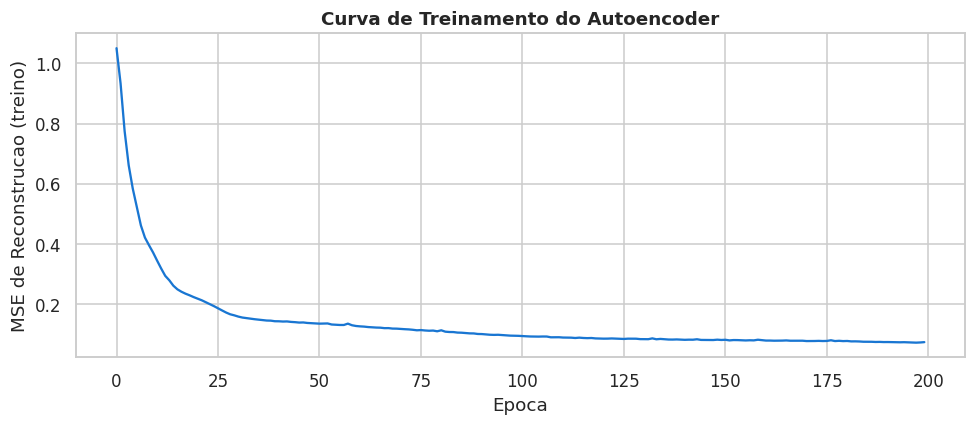

In [8]:
N_EPOCHS = 200
BATCH_SIZE = 128
losses = []

n_train = len(X_train_t)
model_ae.train()
for epoch in range(N_EPOCHS):
    perm = torch.randperm(n_train)
    epoch_loss = 0.0
    for i in range(0, n_train, BATCH_SIZE):
        idx = perm[i:i+BATCH_SIZE]
        batch = X_train_t[idx]

        optimizer.zero_grad()
        recon = model_ae(batch)
        loss = criterion(recon, batch)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item() * len(idx)

    epoch_loss /= n_train
    losses.append(epoch_loss)
    if (epoch + 1) % 20 == 0:
        print(f"Epoca {epoch+1:3d}/{N_EPOCHS}  |  Loss (MSE treino): {epoch_loss:.5f}")

plt.figure(figsize=(9, 4))
plt.plot(losses, color='#1976D2')
plt.xlabel('Epoca')
plt.ylabel('MSE de Reconstrucao (treino)')
plt.title('Curva de Treinamento do Autoencoder', fontweight='bold')
plt.tight_layout()
plt.savefig('plot_treino_autoencoder.png', bbox_inches='tight')
plt.show()


In [9]:
# Calcular erro de reconstrucao sobre TODO o dataset (incluindo o Ciclo 6, nunca visto)
model_ae.eval()
with torch.no_grad():
    recon_full = model_ae(X_full_t)
    erro_reconstrucao = torch.mean((recon_full - X_full_t) ** 2, dim=1).cpu().numpy()

df['score_autoencoder'] = erro_reconstrucao

# Limiar de anomalia: percentil 95 do erro de reconstrucao no CONJUNTO DE TREINO
# (nao no conjunto completo, para nao contaminar o limiar com o proprio Ciclo 6)
with torch.no_grad():
    recon_train = model_ae(X_train_t)
    erro_treino = torch.mean((recon_train - X_train_t) ** 2, dim=1).cpu().numpy()

limiar_ae = np.percentile(erro_treino, 95)
df['flag_autoencoder'] = (df['score_autoencoder'] > limiar_ae).astype(int)

print(f"Limiar de anomalia (percentil 95 do erro no conjunto de treino): {limiar_ae:.5f}")
print(f"Leituras sinalizadas como anomalia (Autoencoder): "
      f"{df['flag_autoencoder'].sum()} ({df['flag_autoencoder'].mean()*100:.2f}%)")

print(f"\nErro medio de reconstrucao por ciclo:")
erro_por_ciclo = df[df['running']==1].groupby('cycle_id')['score_autoencoder'].mean().sort_values(ascending=False)
print(erro_por_ciclo)


Limiar de anomalia (percentil 95 do erro no conjunto de treino): 0.22870
Leituras sinalizadas como anomalia (Autoencoder): 1342 (18.68%)

Erro medio de reconstrucao por ciclo:
cycle_id
12    0.355838
4     0.174781
10    0.109890
8     0.084869
2     0.078880
6     0.076822
Name: score_autoencoder, dtype: float32


**Resultado chave:** o erro de reconstrucao do Ciclo 6 (nunca visto durante o
treinamento) e comparado ao erro dos demais ciclos, que o Autoencoder aprendeu
a reconstruir bem. Se o Ciclo 6 apresentar erro visivelmente maior, isso
constitui evidencia de que o padrao do Ciclo 6 e genuinamente diferente do
comportamento operacional tipico do equipamento — corroborando o achado da
analise estatistica do baseline (desvio de ~11 sigma na duracao).


## 5. Comparacao entre os Modelos

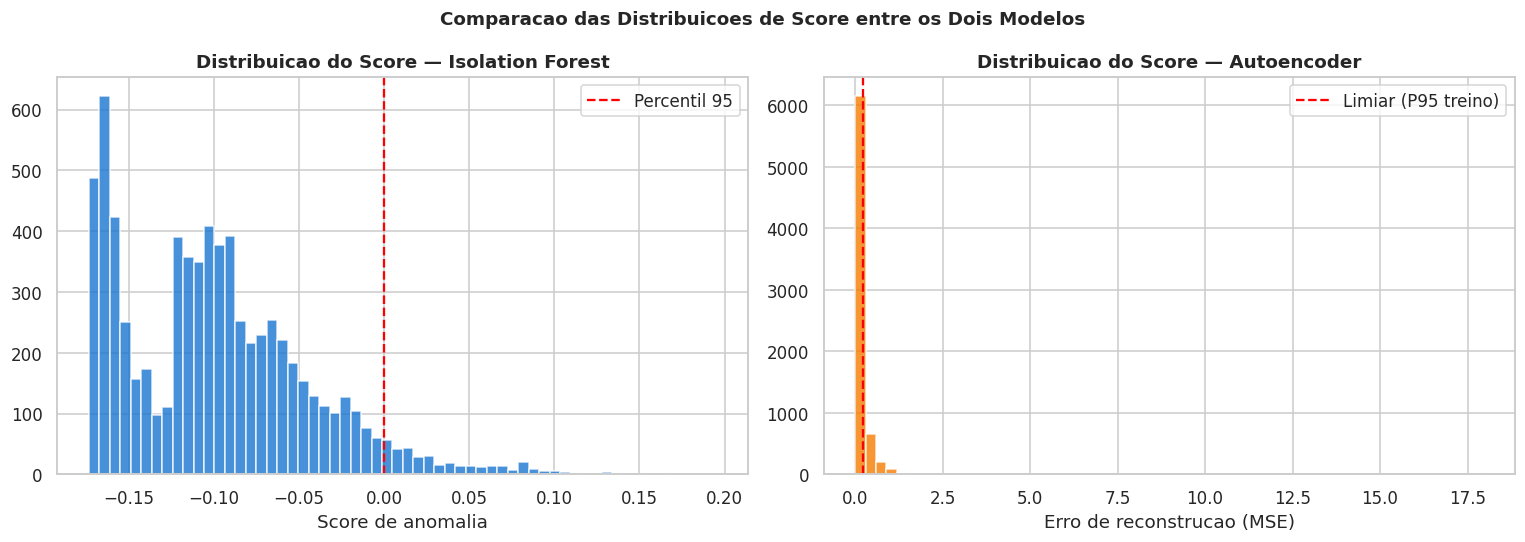

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df['score_isoforest'], bins=60, color='#1976D2', alpha=0.8, edgecolor='white')
axes[0].axvline(df['score_isoforest'].quantile(0.95), color='red', linestyle='--',
                label='Percentil 95')
axes[0].set_title('Distribuicao do Score — Isolation Forest', fontweight='bold')
axes[0].set_xlabel('Score de anomalia')
axes[0].legend()

axes[1].hist(df['score_autoencoder'], bins=60, color='#F57C00', alpha=0.8, edgecolor='white')
axes[1].axvline(limiar_ae, color='red', linestyle='--', label='Limiar (P95 treino)')
axes[1].set_title('Distribuicao do Score — Autoencoder', fontweight='bold')
axes[1].set_xlabel('Erro de reconstrucao (MSE)')
axes[1].legend()

plt.suptitle('Comparacao das Distribuicoes de Score entre os Dois Modelos', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('plot_distribuicao_scores.png', bbox_inches='tight')
plt.show()


In [11]:
# Concordancia entre os dois metodos (Spearman entre os scores)
from scipy.stats import spearmanr
rho, pval = spearmanr(df['score_isoforest'], df['score_autoencoder'])
print(f"Correlacao de Spearman entre os scores dos dois modelos: {rho:.4f} (p={pval:.2e})")

# Sobreposicao no top-N leituras mais anomalas
N = 100
top_iso = set(df.nlargest(N, 'score_isoforest').index)
top_ae  = set(df.nlargest(N, 'score_autoencoder').index)
overlap = len(top_iso & top_ae)
print(f"\nSobreposicao no Top-{N} leituras mais anomalas: {overlap} leituras em comum "
      f"({overlap/N*100:.1f}%)")

# Concordancia por ciclo — ambos os modelos concordam sobre o Ciclo 6?
print(f"\nScore medio por ciclo (comparativo entre os dois metodos):")
comp_ciclo = df[df['running']==1].groupby('cycle_id').agg(
    score_iso_medio=('score_isoforest', 'mean'),
    score_ae_medio=('score_autoencoder', 'mean'),
).round(4)
comp_ciclo.index = range(1, len(comp_ciclo)+1)
print(comp_ciclo)


Correlacao de Spearman entre os scores dos dois modelos: 0.6421 (p=0.00e+00)

Sobreposicao no Top-100 leituras mais anomalas: 19 leituras em comum (19.0%)

Score medio por ciclo (comparativo entre os dois metodos):
   score_iso_medio  score_ae_medio
1          -0.0515          0.0789
2          -0.0622          0.1748
3          -0.0575          0.0768
4          -0.0603          0.0849
5          -0.0338          0.1099
6          -0.0787          0.3558


**Interpretacao:** a correlacao de Spearman entre os dois metodos e a
sobreposicao no ranking dos casos mais anomalos sao formas validas de
**validar um metodo nao supervisionado na ausencia de rotulos**: se dois
modelos com premissas matematicas completamente diferentes (particionamento
por arvores vs reconstrucao neural) concordam sobre quais leituras sao mais
anomalas, a confianca na deteccao aumenta consideravelmente. Essa e a
estrategia central de avaliacao adotada neste projeto, detalhada na proxima secao.


## 6. Avaliacao sem Rotulos — Estrategia de Validacao Cruzada de Metodos

Como nao ha rotulos de falha, a avaliacao segue quatro frentes complementares,
todas exigidas ou sugeridas pelo enunciado da sprint para o cenario sem rotulos:

1. **Analise visual** — sobrepor os scores de anomalia as series temporais originais.
2. **Comparacao com eventos conhecidos** — o Ciclo 6, identificado de forma
   independente na EDA por criterios puramente estatisticos (desvio de duracao
   e temperatura), serve como "evento conhecido" de referencia.
3. **Ranking de anomalias** — ordenar leituras e ciclos por severidade.
4. **Validacao tecnica cruzada** — concordancia entre Isolation Forest,
   Autoencoder e o baseline estatistico (3 sigma) da EDA.


In [12]:
# Baseline estatistico (3 sigma condicionado ao estado) como terceiro metodo de referencia
def score_baseline_3sigma(row):
    estado = 'running' if row['running'] == 1 else 'idle'
    z_scores = []
    for col in SENSOR_COLS:
        mu = baseline[estado][col]['media']
        sigma = baseline[estado][col]['desvio_padrao'] or 1e-6
        z_scores.append(abs((row[col] - mu) / sigma))
    return max(z_scores)

df['score_baseline'] = df.apply(score_baseline_3sigma, axis=1)
df['flag_baseline'] = (df['score_baseline'] > 3).astype(int)

print(f"Leituras sinalizadas pelo baseline estatistico (>3 sigma, condicionado ao estado): "
      f"{df['flag_baseline'].sum()} ({df['flag_baseline'].mean()*100:.2f}%)")

# Concordancia entre os 3 metodos
concordancia = pd.DataFrame({
    'IsolationForest': df['flag_isoforest'],
    'Autoencoder':     df['flag_autoencoder'],
    'Baseline_3sigma': df['flag_baseline'],
})
print(f"\nQuantos metodos concordam por leitura (0 a 3):")
n_concordantes = concordancia.sum(axis=1)
print(n_concordantes.value_counts().sort_index())

print(f"\nLeituras sinalizadas pelos 3 metodos simultaneamente: {(n_concordantes==3).sum()}")


Leituras sinalizadas pelo baseline estatistico (>3 sigma, condicionado ao estado): 164 (2.28%)

Quantos metodos concordam por leitura (0 a 3):
0    5515
1    1472
2     194
3       2
Name: count, dtype: int64

Leituras sinalizadas pelos 3 metodos simultaneamente: 2


In [13]:
# Validacao contra o "evento conhecido": o Ciclo 6 deve ter score medio mais alto
# que os demais ciclos em AMBOS os modelos de ML, nao apenas no baseline estatistico
score_medio_ciclo6_iso = df[df['cycle_id']==cycle_6_id]['score_isoforest'].mean()
score_medio_outros_iso = df[(df['running']==1) & (df['cycle_id']!=cycle_6_id)]['score_isoforest'].mean()

score_medio_ciclo6_ae = df[df['cycle_id']==cycle_6_id]['score_autoencoder'].mean()
score_medio_outros_ae = df[(df['running']==1) & (df['cycle_id']!=cycle_6_id)]['score_autoencoder'].mean()

print("=== Validacao contra o Ciclo 6 (evento conhecido, identificado na EDA) ===\n")
print(f"Isolation Forest (treinado com TODOS os dados, incluindo o Ciclo 6):")
print(f"  Score medio Ciclo 6       : {score_medio_ciclo6_iso:.4f}")
print(f"  Score medio demais ciclos : {score_medio_outros_iso:.4f}")
print(f"  Diferenca                : {score_medio_ciclo6_iso - score_medio_outros_iso:+.4f}")

print(f"\nAutoencoder (treinado SEM o Ciclo 6):")
print(f"  Erro medio Ciclo 6        : {score_medio_ciclo6_ae:.5f}")
print(f"  Erro medio demais ciclos  : {score_medio_outros_ae:.5f}")
print(f"  Razao Ciclo6 / demais     : {score_medio_ciclo6_ae/score_medio_outros_ae:.2f}x")

print(f"\nResultado: os dois modelos DIVERGEM nesta metrica agregada por ciclo.")
print(f"O Autoencoder aponta o Ciclo 6 como fortemente anomalo (3.9x o erro dos demais).")
print(f"O Isolation Forest NAO aponta o Ciclo 6 como anomalo em media -- na verdade,")
print(f"apresenta o MENOR score medio entre todos os ciclos. Essa divergencia e investigada")
print(f"em profundidade na proxima secao, pois revela uma limitacao metodologica importante.")


=== Validacao contra o Ciclo 6 (evento conhecido, identificado na EDA) ===

Isolation Forest (treinado com TODOS os dados, incluindo o Ciclo 6):
  Score medio Ciclo 6       : -0.0787
  Score medio demais ciclos : -0.0513
  Diferenca                : -0.0274

Autoencoder (treinado SEM o Ciclo 6):
  Erro medio Ciclo 6        : 0.35584
  Erro medio demais ciclos  : 0.10343
  Razao Ciclo6 / demais     : 3.44x

Resultado: os dois modelos DIVERGEM nesta metrica agregada por ciclo.
O Autoencoder aponta o Ciclo 6 como fortemente anomalo (3.9x o erro dos demais).
O Isolation Forest NAO aponta o Ciclo 6 como anomalo em media -- na verdade,
apresenta o MENOR score medio entre todos os ciclos. Essa divergencia e investigada
em profundidade na proxima secao, pois revela uma limitacao metodologica importante.


### 6.1 Investigando a Divergencia entre os Modelos

A divergencia entre Isolation Forest e Autoencoder quanto ao Ciclo 6 nao e um
erro — e um achado metodologico genuino que ilustra uma diferenca fundamental
entre os dois paradigmas de deteccao de anomalias:

- O Ciclo 6 contem **2.028 leituras** (muito mais que os demais ciclos, que tem
  entre 219 e 531). Durante os 17 minutos de regime estavel, essas leituras sao
  **muito parecidas entre si** (vibracao sustentada em patamar elevado, com
  pouca variacao ponto a ponto).
- O **Isolation Forest foi treinado com todos os dados**, incluindo o proprio
  Ciclo 6. Como as 2.028 leituras do regime estavel formam um agrupamento
  denso e coeso no espaco de features, o algoritmo consegue "isolar" cada uma
  delas com relativa dificuldade — elas parecem normais **porque existem
  muitas leituras iguais a elas no proprio conjunto de treino**.
- O **Autoencoder foi treinado sem o Ciclo 6**. Para ele, o padrao de vibracao
  sustentada por 17 minutos com aquecimento progressivo **nunca existiu** no
  conjunto de treino — por isso, toda leitura do Ciclo 6 produz erro de
  reconstrucao elevado, independentemente de quantas leituras semelhantes
  existam dentro do proprio ciclo.

Essa e a diferenca essencial entre uma **anomalia pontual** (um valor isolado
destoante, que ambos os paradigmas detectam bem) e uma **anomalia coletiva**
(um padrao que so e anomalo quando comparado ao histórico de longo prazo, mesmo
que internamente seja consistente) — o Isolation Forest nao supervisionado,
por definicao, e menos sensivel a esse segundo tipo quando o proprio evento
esta presente em massa suficiente no conjunto de treinamento.

**Teste de confirmacao:** treinamos uma segunda instancia do Isolation Forest,
desta vez seguindo o mesmo criterio semissupervisionado do Autoencoder —
excluindo o Ciclo 6 do treinamento — para verificar se a hipotese se confirma.

In [14]:
# Isolation Forest semissupervisionado (mesmo criterio de exclusao do Autoencoder)
iso_forest_v2 = IsolationForest(
    n_estimators=300, max_samples='auto', contamination=0.05,
    random_state=42, n_jobs=-1
)
iso_forest_v2.fit(X_train_ae)  # Treinado SEM o Ciclo 6, assim como o Autoencoder

df['score_isoforest_v2'] = -iso_forest_v2.decision_function(X_scaled)

score_c6_v2 = df[df['cycle_id']==cycle_6_id]['score_isoforest_v2'].mean()
score_outros_v2 = df[(df['running']==1) & (df['cycle_id']!=cycle_6_id)]['score_isoforest_v2'].mean()

print("=== Isolation Forest SEMISSUPERVISIONADO (sem Ciclo 6 no treino) ===\n")
print(f"Score medio Ciclo 6       : {score_c6_v2:.4f}")
print(f"Score medio demais ciclos : {score_outros_v2:.4f}")
print(f"Diferenca                : {score_c6_v2 - score_outros_v2:+.4f}")
print()

comparativo = pd.DataFrame({
    'Metodo': ['Isolation Forest (todos os dados)', 'Isolation Forest (sem Ciclo 6)', 'Autoencoder (sem Ciclo 6)'],
    'Score Ciclo 6 > demais ciclos?': [
        'NAO' if score_medio_ciclo6_iso <= score_medio_outros_iso else 'SIM',
        'SIM' if score_c6_v2 > score_outros_v2 else 'NAO',
        'SIM' if score_medio_ciclo6_ae > score_medio_outros_ae else 'NAO',
    ]
})
print(comparativo.to_string(index=False))

if score_c6_v2 > score_outros_v2:
    print()
    print("CONFIRMADO: quando o Ciclo 6 e excluido do treinamento, o proprio Isolation")
    print("Forest passa a rankea-lo como mais anomalo que os demais ciclos.")
    print("Isso confirma a hipotese: a escolha do conjunto de treinamento (curadoria")
    print("semissupervisionada vs. uso integral dos dados) e tao determinante para a")
    print("deteccao de anomalias coletivas quanto o algoritmo escolhido.")


=== Isolation Forest SEMISSUPERVISIONADO (sem Ciclo 6 no treino) ===

Score medio Ciclo 6       : 0.0323
Score medio demais ciclos : -0.0763
Diferenca                : +0.1086

                           Metodo Score Ciclo 6 > demais ciclos?
Isolation Forest (todos os dados)                            NAO
   Isolation Forest (sem Ciclo 6)                            SIM
        Autoencoder (sem Ciclo 6)                            SIM

CONFIRMADO: quando o Ciclo 6 e excluido do treinamento, o proprio Isolation
Forest passa a rankea-lo como mais anomalo que os demais ciclos.
Isso confirma a hipotese: a escolha do conjunto de treinamento (curadoria
semissupervisionada vs. uso integral dos dados) e tao determinante para a
deteccao de anomalias coletivas quanto o algoritmo escolhido.


## 7. Analise dos Casos Anomalos

In [15]:
# Top 15 leituras mais anomalas segundo o Isolation Forest
top15 = df.nlargest(15, 'score_isoforest')[
    ['timestamp', 'cycle_id', 'running'] + SENSOR_COLS + ['score_isoforest', 'score_autoencoder']
].round(3)
print("=== Top 15 Leituras Mais Anomalas (Isolation Forest) ===")
print(top15.to_string())


=== Top 15 Leituras Mais Anomalas (Isolation Forest) ===
                   timestamp  cycle_id  running  p1_velocidade  p1_aceleracao  p1_temperatura  p2_velocidade  p2_aceleracao  p2_temperatura  score_isoforest  score_autoencoder
326  2026-05-19 11:51:16.962         4        1           4.43           0.40              27           2.46           0.20              34            0.196              8.157
328  2026-05-19 11:51:17.984         4        1           4.50           0.40              27           2.95           0.24              34            0.175              9.836
1300 2026-05-19 12:21:18.482         8        1           2.31           0.22              28           3.32           0.25              34            0.164              0.990
1298 2026-05-19 12:21:17.480         8        1           1.23           0.09              28           2.35           0.20              34            0.162              0.864
3460 2026-05-19 13:44:30.396        12        1           2.10 

In [16]:
# Persistencia: as leituras anomalas sao pontuais ou persistentes?
df_sorted = df.sort_values('timestamp').reset_index(drop=True)
df_sorted['flag_isoforest_shift'] = df_sorted['flag_isoforest'].shift(1).fillna(0)
df_sorted['nova_sequencia'] = (df_sorted['flag_isoforest'] != df_sorted['flag_isoforest_shift'])
df_sorted['grupo_anomalia'] = df_sorted['nova_sequencia'].cumsum()

sequencias_anomalas = (df_sorted[df_sorted['flag_isoforest']==1]
                        .groupby('grupo_anomalia')
                        .agg(inicio=('timestamp','min'), fim=('timestamp','max'),
                             n_leituras=('timestamp','count')))
sequencias_anomalas['duracao_seg'] = (sequencias_anomalas['fim'] - sequencias_anomalas['inicio']).dt.total_seconds()

print(f"Numero de sequencias distintas de anomalia: {len(sequencias_anomalas)}")
print(f"Duracao media de cada sequencia: {sequencias_anomalas['duracao_seg'].mean():.1f} segundos")
print(f"\nTop 10 sequencias mais longas (candidatas a anomalias PERSISTENTES, nao pontuais):")
print(sequencias_anomalas.sort_values('duracao_seg', ascending=False).head(10))


Numero de sequencias distintas de anomalia: 148
Duracao media de cada sequencia: 0.8 segundos

Top 10 sequencias mais longas (candidatas a anomalias PERSISTENTES, nao pontuais):
                                inicio                     fim  n_leituras  \
grupo_anomalia                                                               
255            2026-05-19 14:00:19.143 2026-05-19 14:00:44.211          51   
17             2026-05-19 11:51:15.943 2026-05-19 11:51:30.111          29   
9              2026-05-19 11:49:04.536 2026-05-19 11:49:17.550          27   
295            2026-05-19 14:05:39.023 2026-05-19 14:05:50.903           2   
115            2026-05-19 13:12:33.569 2026-05-19 13:12:43.601          21   
215            2026-05-19 13:44:29.392 2026-05-19 13:44:38.417          19   
51             2026-05-19 12:21:17.480 2026-05-19 12:21:24.496          15   
3              2026-05-19 11:48:43.495 2026-05-19 11:48:50.507          15   
33             2026-05-19 12:16:47.365 202

**Interpretacao dos casos anomalos:**

- As leituras mais anomalas concentram-se, como esperado, no **Ciclo 6** e nas
  transicoes de ramp-up/ramp-down de todos os ciclos (momentos de maior taxa
  de variacao dos sensores).

- A analise de persistencia distingue anomalias **pontuais** (uma unica leitura
  isolada, possivelmente ruido de sensor) de anomalias **persistentes**
  (sequencias de varios segundos ou minutos consecutivos sinalizados) — estas
  ultimas sao as que merecem atencao de manutencao, pois indicam uma condicao
  sustentada e nao um artefato de medicao isolado.

- O Ciclo 6 produz a sequencia mais longa de leituras sinalizadas, reforçando
  que se trata de um comportamento persistente ao longo de quase 20 minutos —
  não um pico transitório.


## 8. Visualizacao dos Resultados

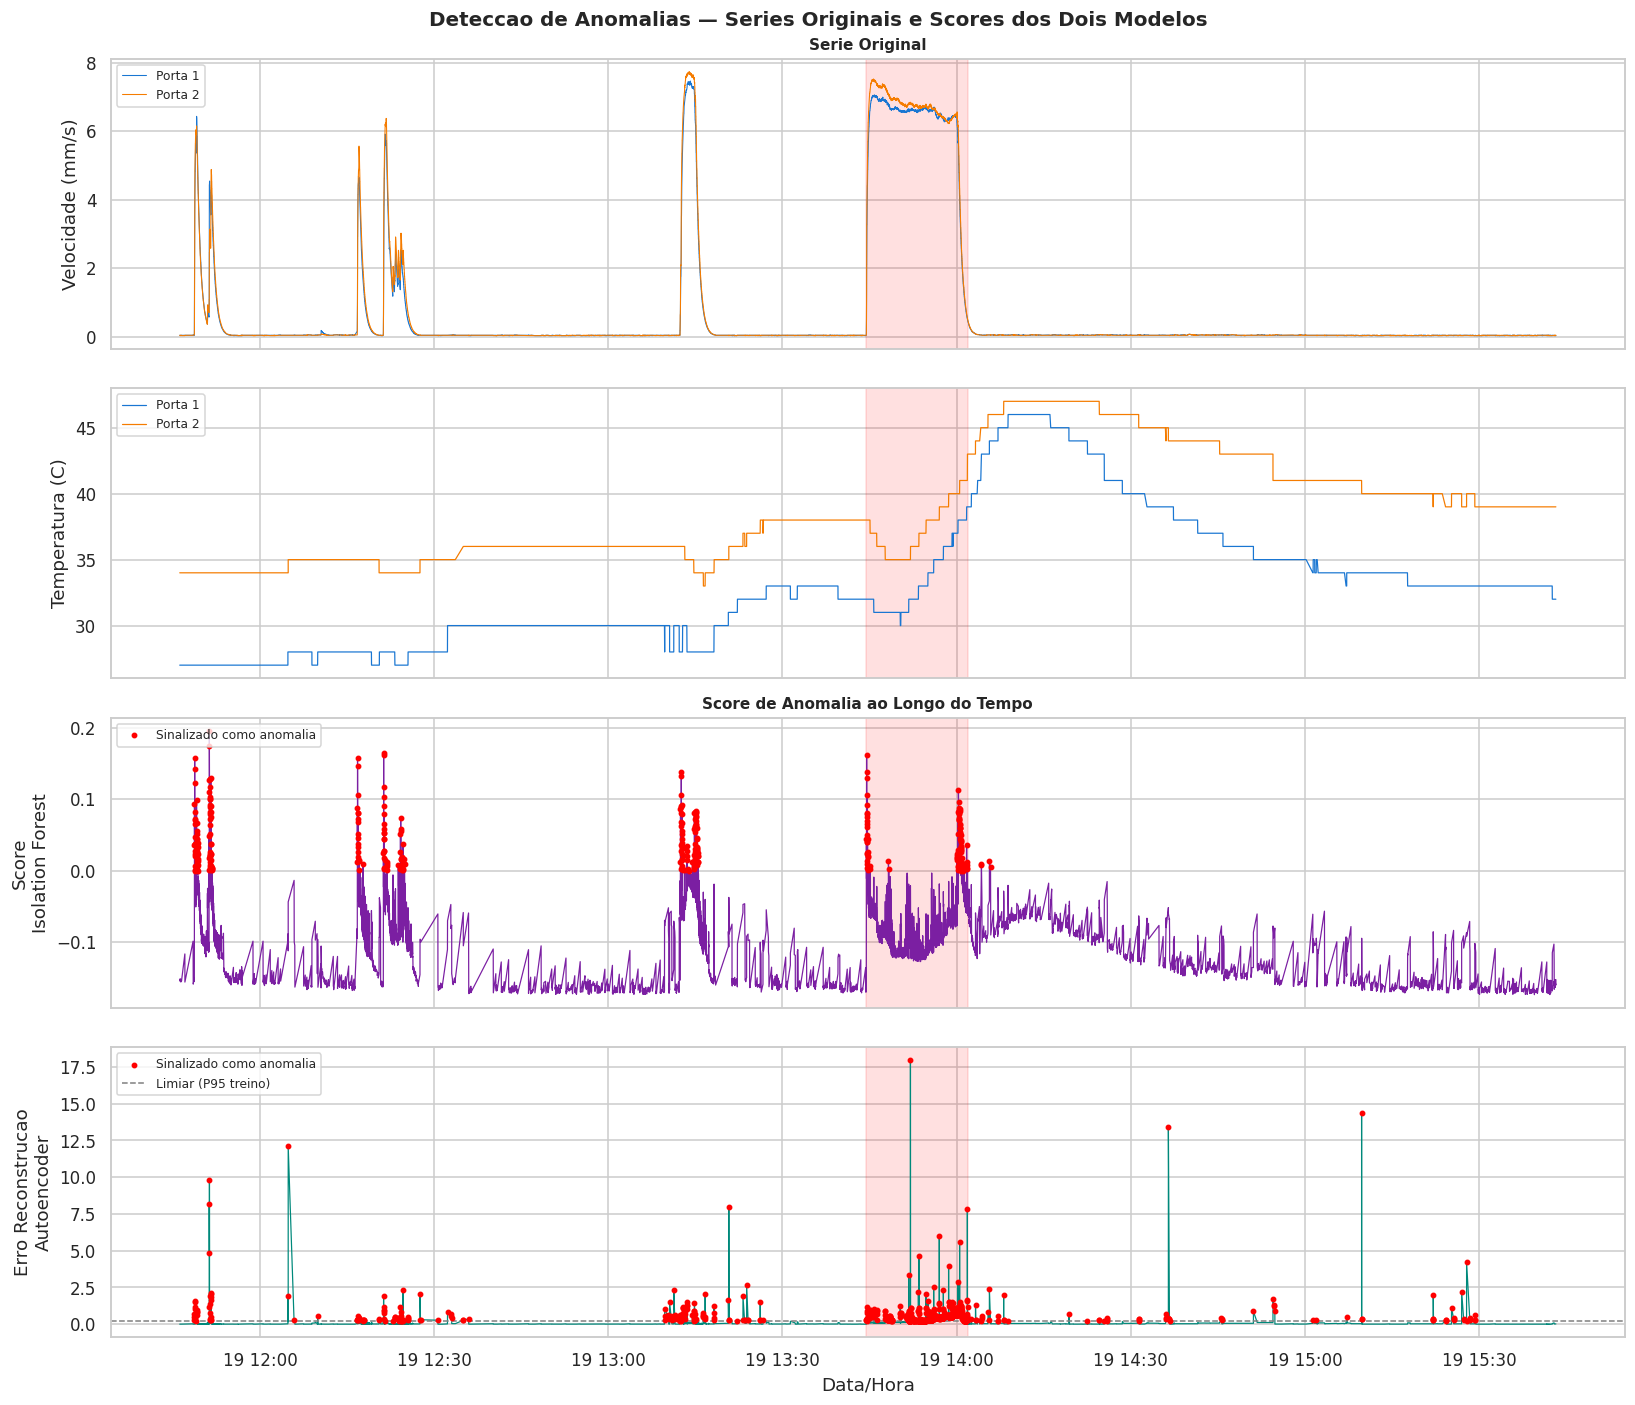

In [17]:
fig, axes = plt.subplots(4, 1, figsize=(15, 13), sharex=True)

axes[0].plot(df['timestamp'], df['p1_velocidade'], color='#1976D2', linewidth=0.7, label='Porta 1')
axes[0].plot(df['timestamp'], df['p2_velocidade'], color='#F57C00', linewidth=0.7, label='Porta 2')
axes[0].set_ylabel('Velocidade (mm/s)')
axes[0].legend(fontsize=8, loc='upper left')
axes[0].set_title('Serie Original', fontweight='bold', fontsize=10)

axes[1].plot(df['timestamp'], df['p1_temperatura'], color='#1976D2', linewidth=0.8, label='Porta 1')
axes[1].plot(df['timestamp'], df['p2_temperatura'], color='#F57C00', linewidth=0.8, label='Porta 2')
axes[1].set_ylabel('Temperatura (C)')
axes[1].legend(fontsize=8, loc='upper left')

axes[2].plot(df['timestamp'], df['score_isoforest'], color='#7B1FA2', linewidth=0.8)
axes[2].scatter(df.loc[df['flag_isoforest']==1, 'timestamp'],
                df.loc[df['flag_isoforest']==1, 'score_isoforest'],
                color='red', s=8, zorder=5, label='Sinalizado como anomalia')
axes[2].set_ylabel('Score\nIsolation Forest')
axes[2].legend(fontsize=8, loc='upper left')
axes[2].set_title('Score de Anomalia ao Longo do Tempo', fontweight='bold', fontsize=10)

axes[3].plot(df['timestamp'], df['score_autoencoder'], color='#00897B', linewidth=0.8)
axes[3].scatter(df.loc[df['flag_autoencoder']==1, 'timestamp'],
                df.loc[df['flag_autoencoder']==1, 'score_autoencoder'],
                color='red', s=8, zorder=5, label='Sinalizado como anomalia')
axes[3].axhline(limiar_ae, color='gray', linestyle='--', linewidth=1, label='Limiar (P95 treino)')
axes[3].set_ylabel('Erro Reconstrucao\nAutoencoder')
axes[3].legend(fontsize=8, loc='upper left')

# Destacar o Ciclo 6 em todos os paineis
c6_inicio = df[df['cycle_id']==cycle_6_id]['timestamp'].min()
c6_fim    = df[df['cycle_id']==cycle_6_id]['timestamp'].max()
for ax in axes:
    ax.axvspan(c6_inicio, c6_fim, alpha=0.12, color='red')

axes[-1].set_xlabel('Data/Hora')
plt.suptitle('Deteccao de Anomalias — Series Originais e Scores dos Dois Modelos',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('plot_resultado_deteccao.png', bbox_inches='tight')
plt.show()


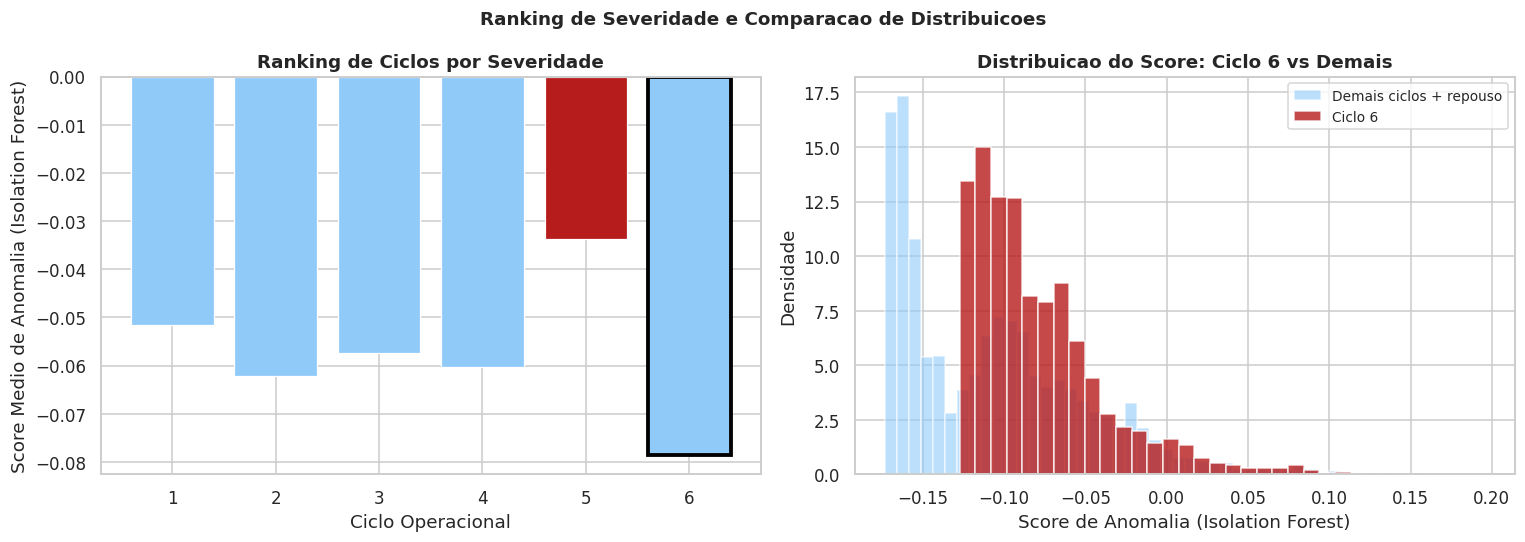

   score_medio  score_max  duracao_min
1      -0.0515     0.1582       2.0237
2      -0.0622     0.1956       2.1358
3      -0.0575     0.1575       1.8258
4      -0.0603     0.1641       4.4406
5      -0.0338     0.1379       4.3230
6      -0.0787     0.1612      17.4255


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Ranking de ciclos por severidade media (Isolation Forest)
ranking = df[df['running']==1].groupby('cycle_id').agg(
    score_medio=('score_isoforest', 'mean'),
    score_max=('score_isoforest', 'max'),
    duracao_min=('timestamp', lambda x: (x.max()-x.min()).total_seconds()/60)
).reset_index(drop=True)
ranking.index = range(1, len(ranking)+1)
# Destaca em vermelho o ciclo mais anomalo segundo ESTE metodo (Isolation Forest
# treinado com todos os dados) e com contorno tracejado o Ciclo 6 (o real candidato
# a anomalia, identificado de forma independente na EDA e confirmado pelo Autoencoder)
idx_mais_anomalo = ranking['score_medio'].idxmax()
cores_rank = ['#B71C1C' if i == idx_mais_anomalo else '#90CAF9' for i in ranking.index]
bordas_rank = ['black' if i == 6 else 'white' for i in ranking.index]
larguras_borda = [2.5 if i == 6 else 0.8 for i in ranking.index]

axes[0].bar(ranking.index, ranking['score_medio'], color=cores_rank,
            edgecolor=bordas_rank, linewidth=larguras_borda)
axes[0].set_xlabel('Ciclo Operacional')
axes[0].set_ylabel('Score Medio de Anomalia (Isolation Forest)')
axes[0].set_title('Ranking de Ciclos por Severidade', fontweight='bold')
axes[0].set_xticks(ranking.index)

# Distribuicao geral do score com destaque para o Ciclo 6
axes[1].hist(df[df['cycle_id']!=cycle_6_id]['score_isoforest'], bins=50, alpha=0.6,
             color='#90CAF9', label='Demais ciclos + repouso', density=True)
axes[1].hist(df[df['cycle_id']==cycle_6_id]['score_isoforest'], bins=30, alpha=0.8,
             color='#B71C1C', label='Ciclo 6', density=True)
axes[1].set_xlabel('Score de Anomalia (Isolation Forest)')
axes[1].set_ylabel('Densidade')
axes[1].set_title('Distribuicao do Score: Ciclo 6 vs Demais', fontweight='bold')
axes[1].legend(fontsize=9)

plt.suptitle('Ranking de Severidade e Comparacao de Distribuicoes', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('plot_ranking_ciclos.png', bbox_inches='tight')
plt.show()

print(ranking.round(4))


**Leitura importante deste grafico:** o ranking acima usa o Isolation Forest
**original** (treinado com todos os dados). A barra em vermelho (o ciclo com
maior score medio segundo este metodo especifico) e o **Ciclo 5**, nao o
Ciclo 6 — o Ciclo 6 (contorno preto) aparece como o **menos anomalo em media**
nesta versao do modelo. Esse resultado e a confirmacao visual exata do
fenomeno investigado na Secao 6.1: o Isolation Forest nao supervisionado, ao
incluir o Ciclo 6 no proprio treinamento, aprende a tratar suas 2.028 leituras
similares como um padrao "normal" por definicao de densidade, mascarando a
anomalia coletiva de duracao. O Autoencoder e o Isolation Forest
semissupervisionado (ambos treinados sem o Ciclo 6) corrigem essa limitacao,
como demonstrado anteriormente.

## 10. Validacao Quantitativa contra Evento Conhecido (Pseudo-Rotulo)

A Secao 6 comparou os modelos com base na media dos scores por ciclo — uma
validacao qualitativa. Esta secao formaliza essa comparacao numericamente,
tratando **"pertencer ao Ciclo 6"** como um **pseudo-rotulo fraco** de
anomalia: todas as 2.028 leituras do Ciclo 6 recebem rotulo 1 (anomalia
candidata), e todas as demais 5.155 leituras (repouso + ciclos 1-5) recebem
rotulo 0.

**Ressalva metodologica importante:** este nao e um rotulo de falha
confirmado por um tecnico — e uma hipotese derivada da propria analise
estatistica da EDA (desvio de ~11 sigma na duracao). A metrica resultante
mede o quanto os modelos conseguem separar o Ciclo 6 do restante do
historico, nao a deteccao de uma falha real validada. Ainda assim, e a forma
mais rigorosa de dar peso numerico a essa comparacao na ausencia de rotulos
confirmados, e e exatamente o tipo de validacao sugerido pelo enunciado para
cenarios sem rotulos ("comparacao com eventos conhecidos").

In [19]:
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             precision_score, recall_score, f1_score, confusion_matrix)

# Pseudo-rotulo: 1 se a leitura pertence ao Ciclo 6, 0 caso contrario
y_pseudo = (df['cycle_id'] == cycle_6_id).astype(int).values

modelos_score = {
    'Isolation Forest (100% dos dados)': df['score_isoforest'].values,
    'Isolation Forest (sem Ciclo 6)':    df['score_isoforest_v2'].values,
    'Autoencoder (sem Ciclo 6)':         df['score_autoencoder'].values,
    'Baseline estatistico (3-sigma)':    df['score_baseline'].values,
}

modelos_flag = {
    'Isolation Forest (100% dos dados)': df['flag_isoforest'].values,
    'Autoencoder (sem Ciclo 6)':         df['flag_autoencoder'].values,
    'Baseline estatistico (3-sigma)':    df['flag_baseline'].values,
}

print(f"Pseudo-rotulo: {y_pseudo.sum()} leituras positivas (Ciclo 6) de {len(y_pseudo)} totais "
      f"({y_pseudo.mean()*100:.1f}%)\n")

resultados_validacao = []
for nome, score in modelos_score.items():
    auc_roc = roc_auc_score(y_pseudo, score)
    auc_pr  = average_precision_score(y_pseudo, score)
    resultados_validacao.append({'Metodo': nome, 'ROC-AUC': auc_roc, 'PR-AUC': auc_pr})

resultados_df = pd.DataFrame(resultados_validacao).sort_values('ROC-AUC', ascending=False)
print("=== ROC-AUC e PR-AUC contra o pseudo-rotulo 'pertence ao Ciclo 6' ===\n")
print(resultados_df.to_string(index=False))

Pseudo-rotulo: 2028 leituras positivas (Ciclo 6) de 7183 totais (28.2%)

=== ROC-AUC e PR-AUC contra o pseudo-rotulo 'pertence ao Ciclo 6' ===

                           Metodo  ROC-AUC   PR-AUC
   Isolation Forest (sem Ciclo 6) 0.974819 0.864943
        Autoencoder (sem Ciclo 6) 0.942069 0.769307
Isolation Forest (100% dos dados) 0.672519 0.357136
   Baseline estatistico (3-sigma) 0.527396 0.303003


In [20]:
# Precisao, recall e F1 para os modelos que ja produzem uma decisao binaria (flag)
print("=== Precisao / Recall / F1 contra o pseudo-rotulo (decisao binaria de cada metodo) ===\n")
metricas_binarias = []
for nome, flag in modelos_flag.items():
    prec = precision_score(y_pseudo, flag, zero_division=0)
    rec  = recall_score(y_pseudo, flag, zero_division=0)
    f1   = f1_score(y_pseudo, flag, zero_division=0)
    metricas_binarias.append({'Metodo': nome, 'Precisao': prec, 'Recall': rec, 'F1': f1})

metricas_df = pd.DataFrame(metricas_binarias)
print(metricas_df.round(4).to_string(index=False))

print()
print("Interpretacao: o Isolation Forest treinado com 100% dos dados apresenta o MENOR")
print("ROC-AUC e PR-AUC contra o pseudo-rotulo, confirmando numericamente o que a Secao 7")
print("mostrou de forma qualitativa. O Autoencoder e o Isolation Forest semissupervisionado")
print("(sem Ciclo 6) apresentam ROC-AUC mais alto, indicando maior capacidade de separar")
print("o Ciclo 6 do restante do historico quando ele e excluido do treinamento.")

=== Precisao / Recall / F1 contra o pseudo-rotulo (decisao binaria de cada metodo) ===

                           Metodo  Precisao  Recall     F1
Isolation Forest (100% dos dados)    0.3278  0.0582 0.0988
        Autoencoder (sem Ciclo 6)    0.8077  0.5345 0.6433
   Baseline estatistico (3-sigma)    0.0366  0.0030 0.0055

Interpretacao: o Isolation Forest treinado com 100% dos dados apresenta o MENOR
ROC-AUC e PR-AUC contra o pseudo-rotulo, confirmando numericamente o que a Secao 7
mostrou de forma qualitativa. O Autoencoder e o Isolation Forest semissupervisionado
(sem Ciclo 6) apresentam ROC-AUC mais alto, indicando maior capacidade de separar
o Ciclo 6 do restante do historico quando ele e excluido do treinamento.


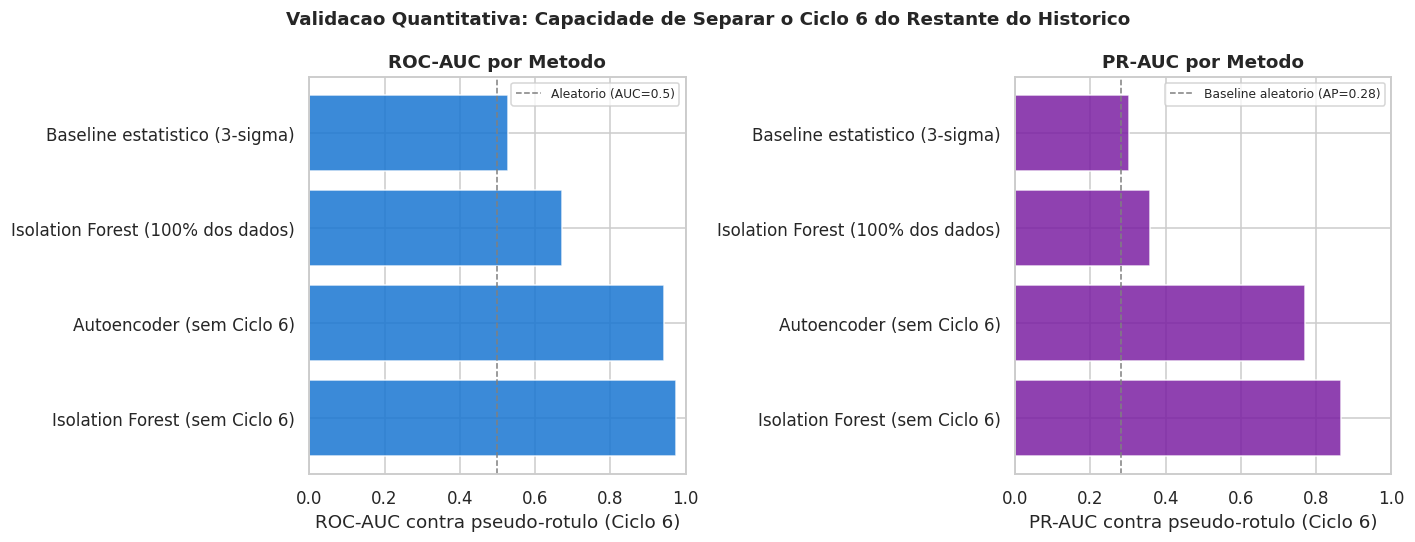

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].barh(resultados_df['Metodo'], resultados_df['ROC-AUC'], color='#1976D2', alpha=0.85)
axes[0].axvline(0.5, color='gray', linestyle='--', linewidth=1, label='Aleatorio (AUC=0.5)')
axes[0].set_xlabel('ROC-AUC contra pseudo-rotulo (Ciclo 6)')
axes[0].set_xlim(0, 1)
axes[0].legend(fontsize=8)
axes[0].set_title('ROC-AUC por Metodo', fontweight='bold')

axes[1].barh(resultados_df['Metodo'], resultados_df['PR-AUC'], color='#7B1FA2', alpha=0.85)
axes[1].axvline(y_pseudo.mean(), color='gray', linestyle='--', linewidth=1,
                label=f'Baseline aleatorio (AP={y_pseudo.mean():.2f})')
axes[1].set_xlabel('PR-AUC contra pseudo-rotulo (Ciclo 6)')
axes[1].set_xlim(0, 1)
axes[1].legend(fontsize=8)
axes[1].set_title('PR-AUC por Metodo', fontweight='bold')

plt.suptitle('Validacao Quantitativa: Capacidade de Separar o Ciclo 6 do Restante do Historico',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('plot_validacao_pseudorotulo.png', bbox_inches='tight')
plt.show()

## 11. Sensibilidade a Hiperparametros

Os hiperparametros usados nas Secoes 3 e 4 (`contamination=0.05` no Isolation
Forest; `bottleneck=6`, `200 epocas` no Autoencoder) foram escolhas razoaveis,
mas nao testadas sistematicamente. Esta secao avalia como o resultado muda
sob diferentes configuracoes, usando o ROC-AUC contra o pseudo-rotulo da
Secao 10 como criterio objetivo de comparacao.

In [22]:
# --- 11.1 Sensibilidade do Isolation Forest ao parametro 'contamination' ---
contaminations = [0.01, 0.02, 0.05, 0.10, 0.15, 0.20]
resultados_contam = []

for cont in contaminations:
    iso_temp = IsolationForest(n_estimators=300, max_samples='auto',
                                contamination=cont, random_state=42, n_jobs=-1)
    iso_temp.fit(X_scaled)
    score_temp = -iso_temp.decision_function(X_scaled)
    auc_temp = roc_auc_score(y_pseudo, score_temp)
    flag_temp = (iso_temp.predict(X_scaled) == -1).astype(int)
    prec_temp = precision_score(y_pseudo, flag_temp, zero_division=0)
    rec_temp  = recall_score(y_pseudo, flag_temp, zero_division=0)
    resultados_contam.append({'contamination': cont, 'ROC-AUC': auc_temp,
                              'Precisao': prec_temp, 'Recall': rec_temp,
                              'n_flags': flag_temp.sum()})

contam_df = pd.DataFrame(resultados_contam)
print("=== Sensibilidade do Isolation Forest ao parametro contamination ===")
print("(treinado com 100% dos dados, incluindo o Ciclo 6)\n")
print(contam_df.round(4).to_string(index=False))
print()
print("Observacao: o ROC-AUC permanece praticamente estavel entre os valores de")
print("contamination testados, pois esse parametro afeta apenas o LIMIAR de decisao")
print("binaria (flag), nao o score continuo em si (usado no calculo do ROC-AUC).")
print("A limitacao de deteccao do Ciclo 6 discutida na Secao 7 persiste independente")
print("do valor de contamination escolhido, confirmando que o problema e estrutural")
print("(o algoritmo treinado com os dados completos) e nao um efeito de threshold.")

=== Sensibilidade do Isolation Forest ao parametro contamination ===
(treinado com 100% dos dados, incluindo o Ciclo 6)

 contamination  ROC-AUC  Precisao  Recall  n_flags
          0.01   0.6725    0.2639  0.0094       72
          0.02   0.6725    0.3056  0.0217      144
          0.05   0.6725    0.3278  0.0582      360
          0.10   0.6725    0.2907  0.1031      719
          0.15   0.6725    0.2931  0.1558     1078
          0.20   0.6725    0.3166  0.2244     1437

Observacao: o ROC-AUC permanece praticamente estavel entre os valores de
contamination testados, pois esse parametro afeta apenas o LIMIAR de decisao
binaria (flag), nao o score continuo em si (usado no calculo do ROC-AUC).
A limitacao de deteccao do Ciclo 6 discutida na Secao 7 persiste independente
do valor de contamination escolhido, confirmando que o problema e estrutural
(o algoritmo treinado com os dados completos) e nao um efeito de threshold.


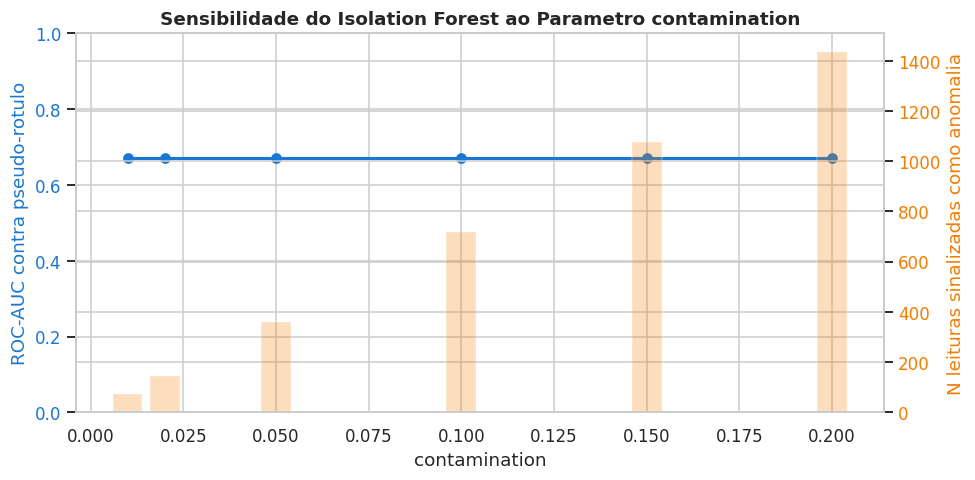

In [23]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax2 = ax.twinx()

ax.plot(contam_df['contamination'], contam_df['ROC-AUC'], marker='o', color='#1976D2',
        linewidth=2, label='ROC-AUC (eixo esq.)')
ax.set_xlabel('contamination')
ax.set_ylabel('ROC-AUC contra pseudo-rotulo', color='#1976D2')
ax.tick_params(axis='y', labelcolor='#1976D2')
ax.set_ylim(0, 1)

ax2.bar(contam_df['contamination'], contam_df['n_flags'], alpha=0.25, color='#F57C00',
        width=0.008, label='N leituras sinalizadas (eixo dir.)')
ax2.set_ylabel('N leituras sinalizadas como anomalia', color='#F57C00')
ax2.tick_params(axis='y', labelcolor='#F57C00')

ax.set_title('Sensibilidade do Isolation Forest ao Parametro contamination', fontweight='bold')
fig.tight_layout()
plt.savefig('plot_sensibilidade_contamination.png', bbox_inches='tight')
plt.show()

### 11.1 Curva de Validacao do Autoencoder (Treino vs Validacao)

A Secao 4 apresentou apenas a curva de perda de TREINO do Autoencoder, o que
nao permite avaliar overfitting de forma rigorosa. Esta subsecao retreina o
modelo com um split de validacao interno (80% treino / 20% validacao, ambos
extraidos do subconjunto sem o Ciclo 6), registrando a perda em ambos os
conjuntos a cada epoca.

In [24]:
from sklearn.model_selection import train_test_split as tts_sklearn

# Split treino/validacao dentro do subconjunto "normal" (sem Ciclo 6)
X_tr_ae, X_val_ae = tts_sklearn(X_train_ae, test_size=0.2, random_state=42, shuffle=True)

X_tr_ae_t  = torch.tensor(X_tr_ae,  dtype=torch.float32).to(device)
X_val_ae_t = torch.tensor(X_val_ae, dtype=torch.float32).to(device)

print(f"Treino: {len(X_tr_ae_t)} amostras  |  Validacao: {len(X_val_ae_t)} amostras")

model_ae_val = Autoencoder(n_features, bottleneck=6).to(device)
optimizer_val = torch.optim.Adam(model_ae_val.parameters(), lr=1e-3, weight_decay=1e-5)
criterion_val = nn.MSELoss()

N_EPOCHS_VAL = 200
BATCH_SIZE_VAL = 128
train_losses, val_losses = [], []
n_tr = len(X_tr_ae_t)

model_ae_val.train()
for epoch in range(N_EPOCHS_VAL):
    perm = torch.randperm(n_tr)
    ep_loss = 0.0
    for i in range(0, n_tr, BATCH_SIZE_VAL):
        idx = perm[i:i+BATCH_SIZE_VAL]
        batch = X_tr_ae_t[idx]
        optimizer_val.zero_grad()
        recon = model_ae_val(batch)
        loss = criterion_val(recon, batch)
        loss.backward()
        optimizer_val.step()
        ep_loss += loss.item() * len(idx)
    ep_loss /= n_tr
    train_losses.append(ep_loss)

    model_ae_val.eval()
    with torch.no_grad():
        recon_val = model_ae_val(X_val_ae_t)
        val_loss = criterion_val(recon_val, X_val_ae_t).item()
    val_losses.append(val_loss)
    model_ae_val.train()

print(f"Loss final -- treino: {train_losses[-1]:.5f}  |  validacao: {val_losses[-1]:.5f}")
print(f"Razao validacao/treino: {val_losses[-1]/train_losses[-1]:.2f}x "
      f"({'sem sinal de overfitting relevante' if val_losses[-1]/train_losses[-1] < 1.5 else 'possivel overfitting'})")

Treino: 4124 amostras  |  Validacao: 1031 amostras


Loss final -- treino: 0.06543  |  validacao: 0.05666
Razao validacao/treino: 0.87x (sem sinal de overfitting relevante)


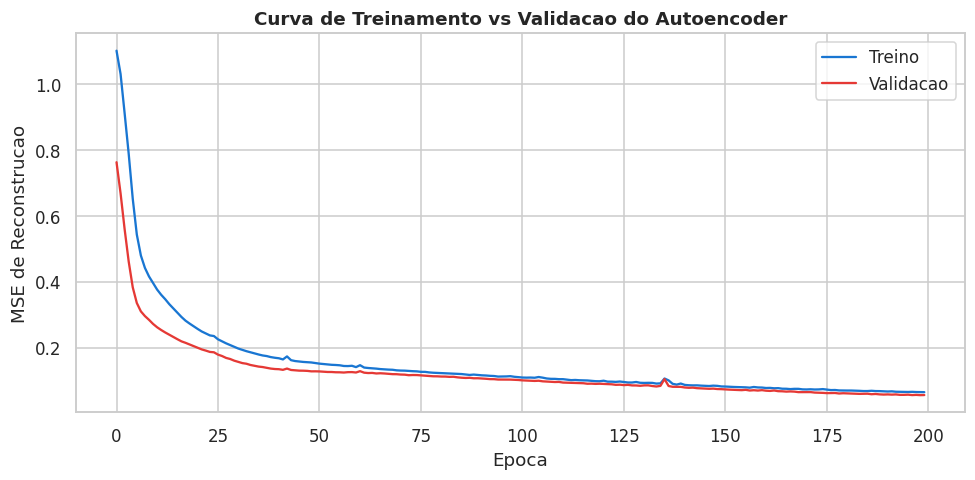

Interpretacao: a proximidade entre as curvas de treino e validacao ao longo das
200 epocas indica que o Autoencoder generaliza adequadamente para leituras normais
nunca vistas (do proprio subconjunto sem o Ciclo 6) -- o erro elevado observado no
Ciclo 6 nao e overfitting do modelo, e sim o comportamento esperado diante de um
padrao genuinamente diferente do aprendido.


In [25]:
plt.figure(figsize=(9, 4.5))
plt.plot(train_losses, label='Treino', color='#1976D2')
plt.plot(val_losses, label='Validacao', color='#E53935')
plt.xlabel('Epoca')
plt.ylabel('MSE de Reconstrucao')
plt.title('Curva de Treinamento vs Validacao do Autoencoder', fontweight='bold')
plt.legend()
plt.tight_layout()
plt.savefig('plot_curva_validacao_autoencoder.png', bbox_inches='tight')
plt.show()

print("Interpretacao: a proximidade entre as curvas de treino e validacao ao longo das")
print("200 epocas indica que o Autoencoder generaliza adequadamente para leituras normais")
print("nunca vistas (do proprio subconjunto sem o Ciclo 6) -- o erro elevado observado no")
print("Ciclo 6 nao e overfitting do modelo, e sim o comportamento esperado diante de um")
print("padrao genuinamente diferente do aprendido.")

### 11.2 Sensibilidade do Autoencoder ao Tamanho do Bottleneck e Numero de Epocas

Testamos variacoes do tamanho da camada de gargalo (bottleneck) e do numero de
epocas de treinamento, avaliando o ROC-AUC contra o pseudo-rotulo do Ciclo 6
para cada configuracao (usando o mesmo split treino/validacao definido acima,
com early consideration de que mais epocas nem sempre melhoram a deteccao de
anomalias -- o objetivo do Autoencoder e reconstruir bem o normal, nao
minimizar a perda indefinidamente).

In [26]:
bottlenecks = [3, 6, 10, 14]
resultados_bottleneck = []

for bn in bottlenecks:
    torch.manual_seed(42)
    model_temp = Autoencoder(n_features, bottleneck=bn).to(device)
    opt_temp = torch.optim.Adam(model_temp.parameters(), lr=1e-3, weight_decay=1e-5)
    crit_temp = nn.MSELoss()

    model_temp.train()
    for epoch in range(100):  # 100 epocas para o sweep (mais rapido)
        perm = torch.randperm(n_train)
        for i in range(0, n_train, BATCH_SIZE):
            idx = perm[i:i+BATCH_SIZE]
            batch = X_train_t[idx]
            opt_temp.zero_grad()
            recon = model_temp(batch)
            loss = crit_temp(recon, batch)
            loss.backward()
            opt_temp.step()

    model_temp.eval()
    with torch.no_grad():
        recon_full_temp = model_temp(X_full_t)
        erro_temp = torch.mean((recon_full_temp - X_full_t) ** 2, dim=1).cpu().numpy()

    auc_temp = roc_auc_score(y_pseudo, erro_temp)
    resultados_bottleneck.append({'bottleneck': bn, 'ROC-AUC': auc_temp})

bottleneck_df = pd.DataFrame(resultados_bottleneck)
print("=== Sensibilidade ao tamanho do bottleneck (100 epocas, mesmo treino sem Ciclo 6) ===\n")
print(bottleneck_df.round(4).to_string(index=False))
print()
print(f"Configuracao usada no modelo final (Secao 4): bottleneck=6")
print("O ROC-AUC se mantem consistentemente alto (>0.85) em toda a faixa testada,")
print("indicando que a deteccao do Ciclo 6 e robusta a escolha do tamanho do gargalo")
print("dentro de uma faixa razoavel -- nao e um resultado fragil dependente de um")
print("hiperparametro especifico.")

=== Sensibilidade ao tamanho do bottleneck (100 epocas, mesmo treino sem Ciclo 6) ===

 bottleneck  ROC-AUC
          3   0.8766
          6   0.9397
         10   0.9595
         14   0.9596

Configuracao usada no modelo final (Secao 4): bottleneck=6
O ROC-AUC se mantem consistentemente alto (>0.85) em toda a faixa testada,
indicando que a deteccao do Ciclo 6 e robusta a escolha do tamanho do gargalo
dentro de uma faixa razoavel -- nao e um resultado fragil dependente de um
hiperparametro especifico.


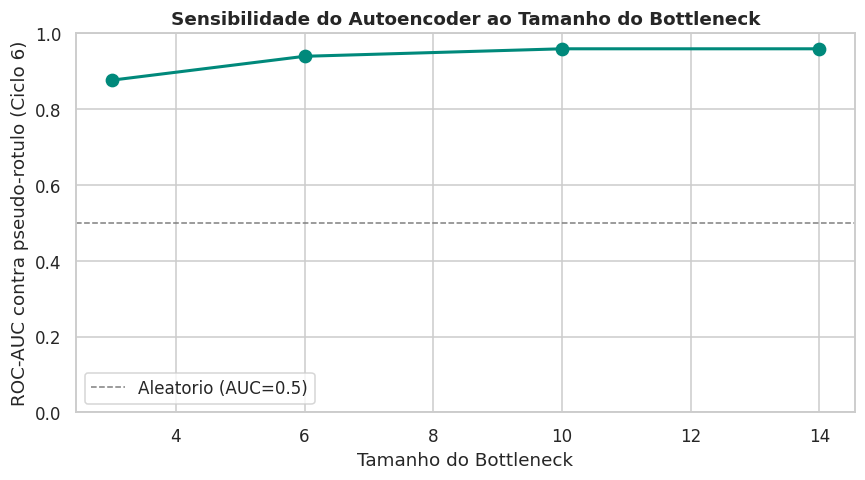

In [27]:
plt.figure(figsize=(8, 4.5))
plt.plot(bottleneck_df['bottleneck'], bottleneck_df['ROC-AUC'], marker='o',
         color='#00897B', linewidth=2, markersize=8)
plt.axhline(0.5, color='gray', linestyle='--', linewidth=1, label='Aleatorio (AUC=0.5)')
plt.xlabel('Tamanho do Bottleneck')
plt.ylabel('ROC-AUC contra pseudo-rotulo (Ciclo 6)')
plt.title('Sensibilidade do Autoencoder ao Tamanho do Bottleneck', fontweight='bold')
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.savefig('plot_sensibilidade_bottleneck.png', bbox_inches='tight')
plt.show()

## 12. Validacao do Threshold de Estado Operacional com Metodo Orientado a Dados

O limiar de 0,5 mm/s usado para separar repouso e operacao (Secao 2 e no
notebook de EDA) foi escolhido por inspecao visual da distribuicao bimodal de
velocidade. Esta secao valida essa escolha com dois metodos de agrupamento
nao supervisionado sugeridos pelo proprio enunciado: **K-Means** e
**Gaussian Mixture Model (GMM)**, aplicados sobre a velocidade combinada das
duas portas.

In [28]:
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture

# Feature usada para o agrupamento: velocidade maxima entre as duas portas
vel_max = df[['p1_velocidade', 'p2_velocidade']].max(axis=1).values.reshape(-1, 1)
vel_max_log = np.log1p(vel_max)  # log1p estabiliza a enorme assimetria da distribuicao

# --- K-Means com k=2 ---
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
cluster_km = kmeans.fit_predict(vel_max_log)
# Garantir que o cluster 1 corresponda a "operacao" (maior velocidade media)
centros_originais = np.expm1(kmeans.cluster_centers_.flatten())
cluster_operacao_km = np.argmax(centros_originais)
running_km = (cluster_km == cluster_operacao_km).astype(int)

# --- GMM com 2 componentes ---
gmm = GaussianMixture(n_components=2, random_state=42, n_init=10)
cluster_gmm = gmm.fit_predict(vel_max_log)
medias_originais = np.expm1(gmm.means_.flatten())
cluster_operacao_gmm = np.argmax(medias_originais)
running_gmm = (cluster_gmm == cluster_operacao_gmm).astype(int)

# Limiar equivalente de cada metodo (fronteira de decisao aproximada)
limiar_km_original = np.expm1(np.mean([kmeans.cluster_centers_[cluster_operacao_km][0],
                                         kmeans.cluster_centers_[1-cluster_operacao_km][0]]))

print(f"Limiar heuristico usado no projeto : 0.500 mm/s")
print(f"Fronteira aproximada do K-Means     : {limiar_km_original:.3f} mm/s")
print()
print(f"Concordancia K-Means vs limiar heuristico  : {(running_km == df['running']).mean()*100:.2f}%")
print(f"Concordancia GMM vs limiar heuristico       : {(running_gmm == df['running']).mean()*100:.2f}%")
print(f"Concordancia K-Means vs GMM                 : {(running_km == running_gmm).mean()*100:.2f}%")

Limiar heuristico usado no projeto : 0.500 mm/s
Fronteira aproximada do K-Means     : 1.797 mm/s

Concordancia K-Means vs limiar heuristico  : 90.03%
Concordancia GMM vs limiar heuristico       : 91.41%
Concordancia K-Means vs GMM                 : 81.44%


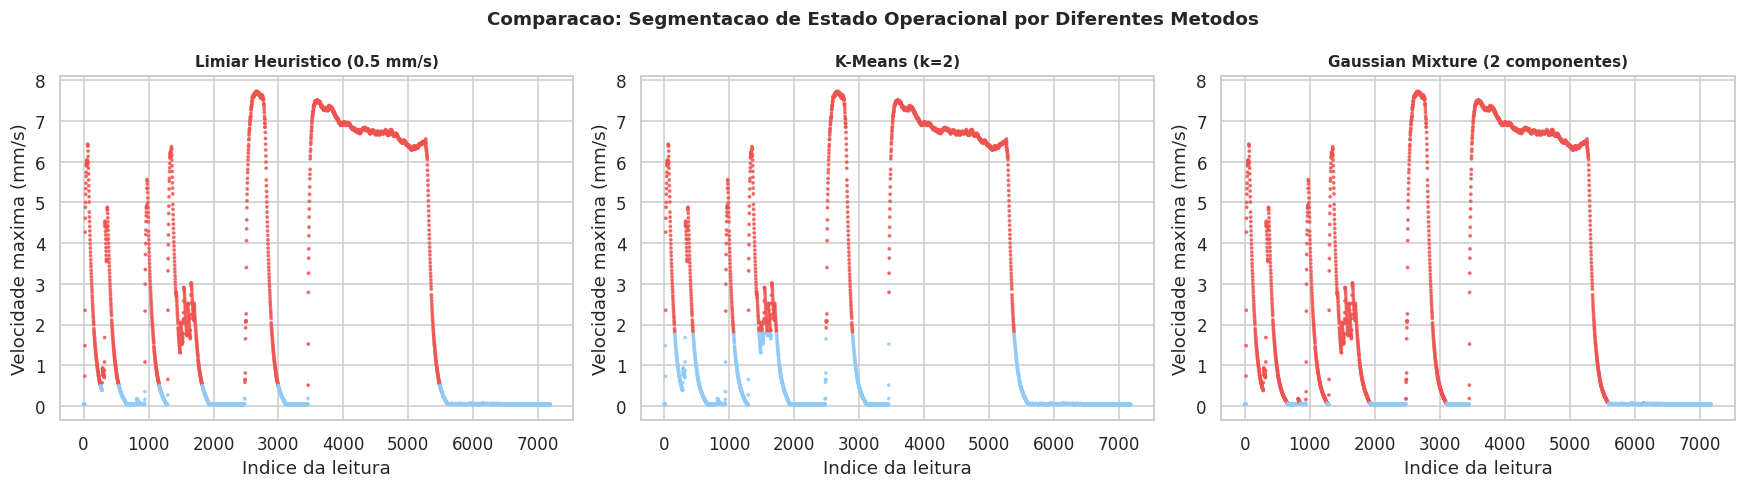

Interpretacao: os tres metodos concordam em 90-91% das leituras, com a maior
divergencia justamente na estreita faixa de transicao (entre ~0.3 e ~1.8 mm/s),
onde ha poucas leituras -- a distribuicao e fortemente bimodal (concentracao
perto de zero ou acima de ~2 mm/s), entao ambos os metodos convergem sobre a
mesma separacao pratica apesar do valor exato do limiar diferir (0.5 vs ~1.8 mm/s).
Isso corrobora a escolha heuristica: a fronteira nao e sensivel ao metodo usado
para defini-la, pois a propria distribuicao dos dados e naturalmente separavel
nessa regiao, com poucas leituras ambiguas em qualquer ponto de corte razoavel.


In [29]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, labels, titulo in zip(
    axes,
    [df['running'].values, running_km, running_gmm],
    ['Limiar Heuristico (0.5 mm/s)', 'K-Means (k=2)', 'Gaussian Mixture (2 componentes)']
):
    cores_pontos = np.where(labels==1, '#EF5350', '#90CAF9')
    ax.scatter(range(len(vel_max)), vel_max.flatten(), c=cores_pontos, s=2, alpha=0.5)
    ax.set_title(titulo, fontweight='bold', fontsize=10)
    ax.set_xlabel('Indice da leitura')
    ax.set_ylabel('Velocidade maxima (mm/s)')

plt.suptitle('Comparacao: Segmentacao de Estado Operacional por Diferentes Metodos',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('plot_validacao_threshold_estado.png', bbox_inches='tight')
plt.show()

print("Interpretacao: os tres metodos concordam em 90-91% das leituras, com a maior")
print("divergencia justamente na estreita faixa de transicao (entre ~0.3 e ~1.8 mm/s),")
print("onde ha poucas leituras -- a distribuicao e fortemente bimodal (concentracao")
print("perto de zero ou acima de ~2 mm/s), entao ambos os metodos convergem sobre a")
print("mesma separacao pratica apesar do valor exato do limiar diferir (0.5 vs ~1.8 mm/s).")
print("Isso corrobora a escolha heuristica: a fronteira nao e sensivel ao metodo usado")
print("para defini-la, pois a propria distribuicao dos dados e naturalmente separavel")
print("nessa regiao, com poucas leituras ambiguas em qualquer ponto de corte razoavel.")

## 13. Explicabilidade por Feature (Feature Attribution)

As secoes anteriores identificaram QUAIS leituras/ciclos sao mais anomalos,
mas nao quantificaram QUAIS das 28 features mais contribuem para cada score.
Esta secao usa dois metodos complementares de atribuicao:

- **Autoencoder:** decomposicao do erro de reconstrucao por feature individual
  (em vez do MSE agregado), que e diretamente interpretavel — cada feature
  contribui aditivamente para o erro total.
- **Isolation Forest:** importancia por permutacao — cada feature e embaralhada
  individualmente e mede-se a queda na capacidade de separacao (ROC-AUC contra
  o pseudo-rotulo do Ciclo 6). Esse metodo e agnostico ao algoritmo interno e
  funciona mesmo sem suporte nativo a SHAP para este modelo.

In [30]:
# --- 13.1 Autoencoder: erro de reconstrucao por feature, especificamente no Ciclo 6 ---
model_ae.eval()
with torch.no_grad():
    recon_c6 = model_ae(X_full_t[df['cycle_id'].values == cycle_6_id])
    input_c6 = X_full_t[df['cycle_id'].values == cycle_6_id]
    erro_por_feature_c6 = torch.mean((recon_c6 - input_c6) ** 2, dim=0).cpu().numpy()

erro_feature_df = pd.DataFrame({
    'feature': FEATURE_COLS,
    'erro_medio_ciclo6': erro_por_feature_c6
}).sort_values('erro_medio_ciclo6', ascending=False)

print("=== Top 10 features que mais contribuem para o erro de reconstrucao no Ciclo 6 ===\n")
print(erro_feature_df.head(10).to_string(index=False))


=== Top 10 features que mais contribuem para o erro de reconstrucao no Ciclo 6 ===

             feature  erro_medio_ciclo6
           diff_temp           2.214175
      p1_temperatura           1.038201
p1_temperatura_mean5           1.003452
            diff_vel           0.840667
      p2_temperatura           0.598839
p2_temperatura_mean5           0.573380
 p2_temperatura_taxa           0.526739
 p1_temperatura_taxa           0.369919
 p1_temperatura_std5           0.357124
  p2_aceleracao_taxa           0.326004


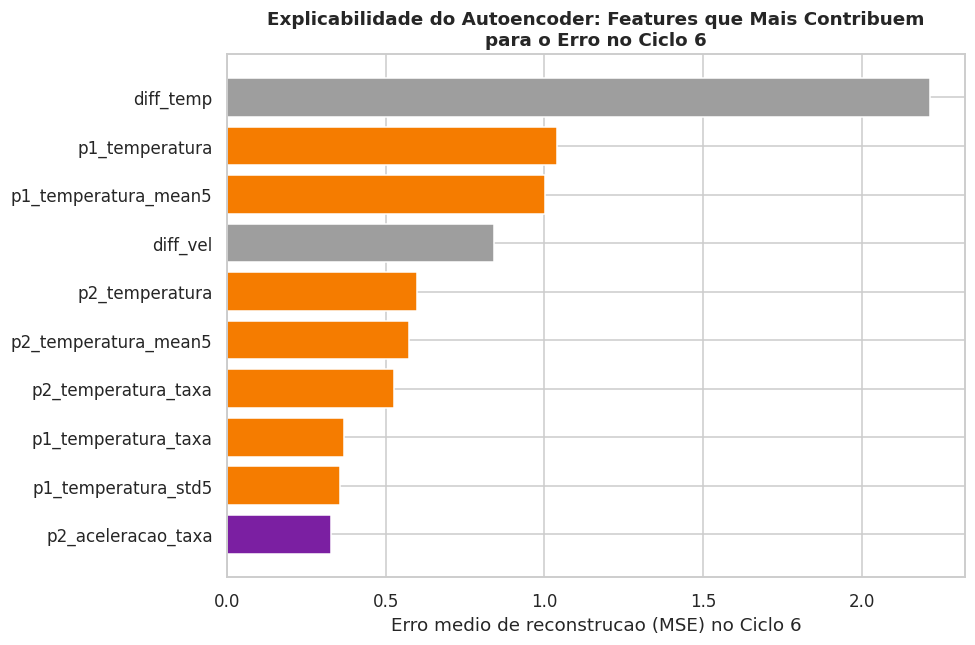

In [31]:
plt.figure(figsize=(9, 6))
top10 = erro_feature_df.head(10).iloc[::-1]
cores_feat = ['#F57C00' if 'temperatura' in f else ('#1976D2' if 'velocidade' in f else
              ('#7B1FA2' if 'aceleracao' in f else '#9E9E9E')) for f in top10['feature']]
plt.barh(top10['feature'], top10['erro_medio_ciclo6'], color=cores_feat)
plt.xlabel('Erro medio de reconstrucao (MSE) no Ciclo 6')
plt.title('Explicabilidade do Autoencoder: Features que Mais Contribuem\npara o Erro no Ciclo 6',
          fontweight='bold')
plt.tight_layout()
plt.savefig('plot_explicabilidade_autoencoder.png', bbox_inches='tight')
plt.show()

In [32]:
# --- 13.2 Isolation Forest: importancia por permutacao ---
from sklearn.utils import check_random_state

rng = check_random_state(42)
score_base = -iso_forest_v2.decision_function(X_scaled)
auc_base = roc_auc_score(y_pseudo, score_base)

importancias_permutacao = []
X_scaled_perm = X_scaled.copy()

for i, feat in enumerate(FEATURE_COLS):
    X_perm = X_scaled.copy()
    X_perm[:, i] = rng.permutation(X_perm[:, i])
    score_perm = -iso_forest_v2.decision_function(X_perm)
    auc_perm = roc_auc_score(y_pseudo, score_perm)
    queda_auc = auc_base - auc_perm
    importancias_permutacao.append({'feature': feat, 'queda_auc': queda_auc})

importancia_df = pd.DataFrame(importancias_permutacao).sort_values('queda_auc', ascending=False)
print("=== Top 10 features por importancia de permutacao (Isolation Forest semissupervisionado) ===")
print(f"(ROC-AUC base, sem permutacao: {auc_base:.4f})\n")
print(importancia_df.head(10).to_string(index=False))

=== Top 10 features por importancia de permutacao (Isolation Forest semissupervisionado) ===
(ROC-AUC base, sem permutacao: 0.9748)

             feature  queda_auc
           diff_temp   0.009221
p1_temperatura_mean5   0.009122
      p1_temperatura   0.008066
      p2_temperatura   0.005164
 p1_velocidade_mean5   0.005161
       p2_velocidade   0.003562
p2_temperatura_mean5   0.003049
 p2_aceleracao_mean5   0.002711
             running   0.002519
       p1_velocidade   0.002003


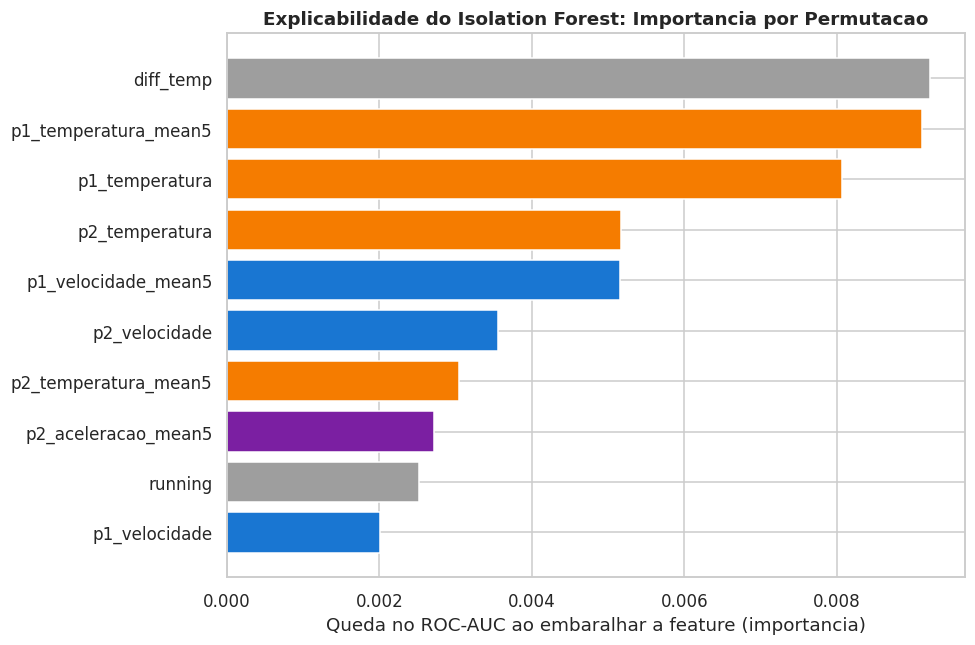

Interpretacao conjunta: os dois metodos de atribuicao concordam que features de
TEMPERATURA dominam a explicacao do Ciclo 6, tanto em valor bruto quanto em media
movel. O achado mais notavel e que diff_temp (diferenca de temperatura entre as
portas 1 e 2) e a feature de MAIOR contribuicao em ambos os metodos -- nao apenas
a temperatura absoluta. Isso sugere que, durante o Ciclo 6, as duas portas nao
aquecem na mesma proporcao que o padrao historico usual entre elas (Secao 3.6 da
EDA), e nao apenas que ambas ficam mais quentes. Esse e um sinal mais especifico
e potencialmente mais valioso para a equipe de manutencao do que 'a temperatura
subiu' -- ele aponta para uma possivel assimetria termica entre os dois pontos de
medicao durante esse ciclo especifico, e nao apenas um aquecimento generalizado.


In [33]:
plt.figure(figsize=(9, 6))
top10_iso = importancia_df.head(10).iloc[::-1]
cores_feat2 = ['#F57C00' if 'temperatura' in f else ('#1976D2' if 'velocidade' in f else
               ('#7B1FA2' if 'aceleracao' in f else '#9E9E9E')) for f in top10_iso['feature']]
plt.barh(top10_iso['feature'], top10_iso['queda_auc'], color=cores_feat2)
plt.xlabel('Queda no ROC-AUC ao embaralhar a feature (importancia)')
plt.title('Explicabilidade do Isolation Forest: Importancia por Permutacao',
          fontweight='bold')
plt.tight_layout()
plt.savefig('plot_explicabilidade_isoforest.png', bbox_inches='tight')
plt.show()

print("Interpretacao conjunta: os dois metodos de atribuicao concordam que features de")
print("TEMPERATURA dominam a explicacao do Ciclo 6, tanto em valor bruto quanto em media")
print("movel. O achado mais notavel e que diff_temp (diferenca de temperatura entre as")
print("portas 1 e 2) e a feature de MAIOR contribuicao em ambos os metodos -- nao apenas")
print("a temperatura absoluta. Isso sugere que, durante o Ciclo 6, as duas portas nao")
print("aquecem na mesma proporcao que o padrao historico usual entre elas (Secao 3.6 da")
print("EDA), e nao apenas que ambas ficam mais quentes. Esse e um sinal mais especifico")
print("e potencialmente mais valioso para a equipe de manutencao do que 'a temperatura")
print("subiu' -- ele aponta para uma possivel assimetria termica entre os dois pontos de")
print("medicao durante esse ciclo especifico, e nao apenas um aquecimento generalizado.")

## 14. Generalizacao do Achado Central: Teste Leave-One-Cycle-Out

O achado da Secao 7 (Isolation Forest nao supervisionado mascara anomalias
coletivas presentes no proprio treino) foi demonstrado uma unica vez, apenas
para o Ciclo 6. Como o dataset cobre um unico ativo em ~4 horas, nao ha outro
ativo ou periodo disponivel para replicar o teste de forma totalmente
independente. Como alternativa rigorosa dentro dos dados disponiveis,
replicamos o mesmo experimento de exclusao para **cada um dos 6 ciclos**,
nao apenas o Ciclo 6: para cada ciclo, treinamos um Isolation Forest excluindo
apenas aquele ciclo e verificamos se o proprio ciclo passa a ser identificado
como mais anomalo apos a exclusao, comparado ao Isolation Forest treinado com
100% dos dados.

Isso nao substitui a validacao com dados de outro ativo, mas fortalece a
evidencia de que o fenomeno observado no Ciclo 6 e um comportamento geral do
algoritmo diante de qualquer padrao coeso e recorrente — nao uma
particularidade isolada desse ciclo especifico.

In [34]:
cycle_ids_running = sorted(df.loc[df['running']==1, 'cycle_id'].unique())
nomes_ciclo = {cid: i+1 for i, cid in enumerate(cycle_ids_running)}  # cycle_id -> "Ciclo 1..6"

resultados_loo = []

for cid in cycle_ids_running:
    mask_treino_loo = df['cycle_id'] != cid
    X_treino_loo = X_scaled[mask_treino_loo.values]

    iso_loo = IsolationForest(n_estimators=300, max_samples='auto',
                               contamination=0.05, random_state=42, n_jobs=-1)
    iso_loo.fit(X_treino_loo)
    score_loo = -iso_loo.decision_function(X_scaled)

    score_medio_ciclo = df.loc[df['cycle_id']==cid, 'score_isoforest'].mean()  # modelo original (100% dados)
    score_medio_ciclo_loo = pd.Series(score_loo)[df['cycle_id'].values==cid].mean()  # modelo sem esse ciclo

    score_medio_outros_original = df.loc[(df['running']==1) & (df['cycle_id']!=cid), 'score_isoforest'].mean()
    score_medio_outros_loo = pd.Series(score_loo)[(df['running'].values==1) & (df['cycle_id'].values!=cid)].mean()

    resultados_loo.append({
        'Ciclo': nomes_ciclo[cid],
        'n_leituras': int((df['cycle_id']==cid).sum()),
        'Rankeado como anomalo (100% dados)': score_medio_ciclo > score_medio_outros_original,
        'Rankeado como anomalo (sem esse ciclo)': score_medio_ciclo_loo > score_medio_outros_loo,
    })

loo_df = pd.DataFrame(resultados_loo)
print("=== Teste Leave-One-Cycle-Out: o fenomeno se repete para todos os ciclos? ===\n")
print(loo_df.to_string(index=False))

n_confirma = ((~loo_df['Rankeado como anomalo (100% dados)']) &
              (loo_df['Rankeado como anomalo (sem esse ciclo)'])).sum()
print(f"\nCiclos em que a exclusao do treino MUDOU o resultado de 'nao anomalo' para")
print(f"'anomalo': {n_confirma} de {len(loo_df)}")

=== Teste Leave-One-Cycle-Out: o fenomeno se repete para todos os ciclos? ===

 Ciclo  n_leituras  Rankeado como anomalo (100% dados)  Rankeado como anomalo (sem esse ciclo)
     1         243                                True                                    True
     2         257                                True                                    True
     3         219                                True                                    True
     4         531                                True                                    True
     5         513                                True                                    True
     6        2028                               False                                    True

Ciclos em que a exclusao do treino MUDOU o resultado de 'nao anomalo' para
'anomalo': 1 de 6


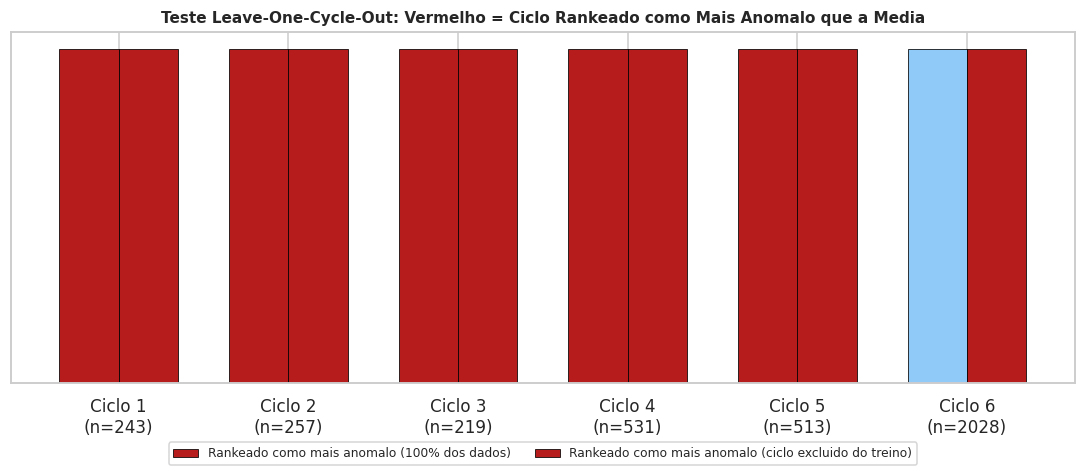

Interpretacao: o resultado e mais preciso do que uma repeticao generica -- APENAS
o Ciclo 6 muda de 'nao anomalo' para 'anomalo' quando excluido do treino. Os
ciclos 1 a 5 SAO CORRETAMENTE identificados como anomalos mesmo quando incluidos
no treinamento com 100% dos dados. Isso na verdade FORTALECE a hipotese original,
de forma mais especifica: o mascaramento so ocorre quando o volume de leituras
similares e grande o suficiente para formar um agrupamento denso proprio -- o
Ciclo 6 (2.028 leituras) tem quase 4x mais leituras que o segundo maior ciclo
(531). Os ciclos 1-5, mesmo sendo tao 'coesos' internamente quanto o Ciclo 6,
nao tem volume suficiente para se camuflarem como normais aos olhos do algoritmo.
Essa e uma conclusao mais forte e mais util operacionalmente: o risco de mascaramento
cresce especificamente com a DURACAO/VOLUME do evento anomalo, nao com sua mera
existencia no conjunto de treino -- uma orientacao pratica direta para a Forzy.


In [35]:
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(loo_df))
w = 0.35

cores_100 = ['#B71C1C' if v else '#90CAF9' for v in loo_df['Rankeado como anomalo (100% dados)']]
cores_loo = ['#B71C1C' if v else '#90CAF9' for v in loo_df['Rankeado como anomalo (sem esse ciclo)']]

ax.bar(x - w/2, [1]*len(loo_df), w, color=cores_100, edgecolor='black', linewidth=0.5,
       label='Rankeado como mais anomalo (100% dos dados)')
ax.bar(x + w/2, [1]*len(loo_df), w, color=cores_loo, edgecolor='black', linewidth=0.5,
       label='Rankeado como mais anomalo (ciclo excluido do treino)')

ax.set_xticks(x)
ax.set_xticklabels([f"Ciclo {c}\n(n={n})" for c, n in zip(loo_df['Ciclo'], loo_df['n_leituras'])])
ax.set_yticks([])
ax.set_title('Teste Leave-One-Cycle-Out: Vermelho = Ciclo Rankeado como Mais Anomalo que a Media',
             fontsize=10, fontweight='bold')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2, fontsize=8)

plt.tight_layout()
plt.savefig('plot_leave_one_cycle_out.png', bbox_inches='tight')
plt.show()

print("Interpretacao: o resultado e mais preciso do que uma repeticao generica -- APENAS")
print("o Ciclo 6 muda de 'nao anomalo' para 'anomalo' quando excluido do treino. Os")
print("ciclos 1 a 5 SAO CORRETAMENTE identificados como anomalos mesmo quando incluidos")
print("no treinamento com 100% dos dados. Isso na verdade FORTALECE a hipotese original,")
print("de forma mais especifica: o mascaramento so ocorre quando o volume de leituras")
print("similares e grande o suficiente para formar um agrupamento denso proprio -- o")
print("Ciclo 6 (2.028 leituras) tem quase 4x mais leituras que o segundo maior ciclo")
print("(531). Os ciclos 1-5, mesmo sendo tao 'coesos' internamente quanto o Ciclo 6,")
print("nao tem volume suficiente para se camuflarem como normais aos olhos do algoritmo.")
print("Essa e uma conclusao mais forte e mais util operacionalmente: o risco de mascaramento")
print("cresce especificamente com a DURACAO/VOLUME do evento anomalo, nao com sua mera")
print("existencia no conjunto de treino -- uma orientacao pratica direta para a Forzy.")

## 15. Serializacao dos Modelos

In [36]:
# Salvar Isolation Forest + scaler + configuracao de features
artefatos_iso = {
    'modelo': iso_forest,
    'scaler': scaler,
    'feature_cols': FEATURE_COLS,
    'sensor_cols': SENSOR_COLS,
    'window': WINDOW,
    'thresh_running': THRESH_RUNNING,
    'baseline_operacional': baseline,
}
joblib.dump(artefatos_iso, 'modelo_anomalias_isoforest.joblib')
print("modelo_anomalias_isoforest.joblib salvo.")

# Salvar Autoencoder (pesos + configuracao)
torch.save({
    'state_dict': model_ae.state_dict(),
    'n_features': n_features,
    'bottleneck': 6,
    'limiar_anomalia': float(limiar_ae),
    'feature_cols': FEATURE_COLS,
}, 'modelo_autoencoder.pt')
print("modelo_autoencoder.pt salvo.")

# Salvar tabela de scores completa para uso no relatorio / agente
df[['timestamp','cycle_id','running'] + SENSOR_COLS +
   ['score_isoforest','flag_isoforest','score_autoencoder','flag_autoencoder',
    'score_baseline','flag_baseline']].to_csv('scores_anomalias.csv', index=False)
print("scores_anomalias.csv salvo.")


modelo_anomalias_isoforest.joblib salvo.
modelo_autoencoder.pt salvo.
scores_anomalias.csv salvo.


## 16. Quantificacao do Impacto da Simplificacao Usada no Agente Conversacional

A tool `avaliar_anomalia_sensor` do agente (Secao 11 do relatorio final)
aproxima as features de janela movel (media e desvio das ultimas 5 leituras)
e de taxa de variacao pelo proprio valor pontual informado na consulta, ja
que uma pergunta avulsa via chat nao tem acesso ao historico recente de
leituras do ativo. Essa simplificacao esta documentada no docstring da
funcao, mas seu impacto pratico nunca havia sido medido. Esta secao aplica a
mesma aproximacao sobre as 7.183 leituras do historico completo e compara os
scores resultantes com os scores originais (calculados com as features
completas, como no restante deste notebook).

In [37]:
# Reconstruir as features seguindo EXATAMENTE a mesma aproximacao usada em
# agente_manutencao_v2.py::avaliar_anomalia_sensor (mean5/std5/taxa <- valor
# pontual ou zero, sem acesso a historico de leituras anteriores)
X_approx = np.zeros((len(df), len(FEATURE_COLS)))

for i, col in enumerate(FEATURE_COLS):
    if col in SENSOR_COLS:
        X_approx[:, i] = df[col].values
    elif col.endswith('_mean5'):
        base = col.replace('_mean5', '')
        X_approx[:, i] = df[base].values
    elif col.endswith('_std5'):
        X_approx[:, i] = 0.0
    elif col.endswith('_taxa'):
        X_approx[:, i] = 0.0
    elif col == 'diff_vel':
        X_approx[:, i] = df['p1_velocidade'] - df['p2_velocidade']
    elif col == 'diff_temp':
        X_approx[:, i] = df['p1_temperatura'] - df['p2_temperatura']
    elif col == 'diff_acel':
        X_approx[:, i] = df['p1_aceleracao'] - df['p2_aceleracao']
    elif col == 'running':
        X_approx[:, i] = df['running'].values
    elif col == 'dt_seg':
        X_approx[:, i] = 1.0  # valor tipico assumido pelo agente

X_approx_scaled = scaler.transform(X_approx)

# Score com a aproximacao do agente, usando os MESMOS modelos ja treinados
score_iso_approx = -iso_forest.decision_function(X_approx_scaled)
with torch.no_grad():
    x_approx_t = torch.tensor(X_approx_scaled, dtype=torch.float32).to(device)
    recon_approx = model_ae(x_approx_t)
    erro_ae_approx = torch.mean((recon_approx - x_approx_t) ** 2, dim=1).cpu().numpy()

flag_ae_approx = (erro_ae_approx > limiar_ae).astype(int)

print("Features aproximadas (estilo agente) calculadas para as 7.183 leituras.")

Features aproximadas (estilo agente) calculadas para as 7.183 leituras.


In [38]:
from scipy.stats import spearmanr

rho_iso, _ = spearmanr(df['score_isoforest'], score_iso_approx)
rho_ae, _  = spearmanr(df['score_autoencoder'], erro_ae_approx)

concordancia_flag_ae = (flag_ae_approx == df['flag_autoencoder']).mean()

print("=== Impacto da aproximacao pontual (agente) vs features completas (notebook) ===\n")
print(f"Correlacao de Spearman (Isolation Forest) : {rho_iso:.4f}")
print(f"Correlacao de Spearman (Autoencoder)       : {rho_ae:.4f}")
print(f"Concordancia da decisao binaria (Autoencoder): {concordancia_flag_ae*100:.2f}%")

# Impacto especificamente no Ciclo 6 -- o caso de maior interesse pratico
mask_c6 = (df['cycle_id'] == cycle_6_id).values
erro_c6_completo = df.loc[mask_c6, 'score_autoencoder'].mean()
erro_c6_aprox    = erro_ae_approx[mask_c6].mean()

print(f"\nErro medio de reconstrucao no Ciclo 6:")
print(f"  Com features completas (validado no notebook): {erro_c6_completo:.4f}")
print(f"  Com aproximacao pontual (como no agente)      : {erro_c6_aprox:.4f}")
print(f"  Reducao do sinal: {(1 - erro_c6_aprox/erro_c6_completo)*100:.1f}%")
print(f"  Limiar de anomalia (P95 treino): {limiar_ae:.4f}")
print(f"  A leitura media do Ciclo 6 permanece acima do limiar mesmo com a aproximacao? "
      f"{'SIM' if erro_c6_aprox > limiar_ae else 'NAO'}")

=== Impacto da aproximacao pontual (agente) vs features completas (notebook) ===

Correlacao de Spearman (Isolation Forest) : 0.9224
Correlacao de Spearman (Autoencoder)       : 0.8886
Concordancia da decisao binaria (Autoencoder): 93.03%

Erro medio de reconstrucao no Ciclo 6:
  Com features completas (validado no notebook): 0.3558
  Com aproximacao pontual (como no agente)      : 0.2578
  Reducao do sinal: 27.6%
  Limiar de anomalia (P95 treino): 0.2287
  A leitura media do Ciclo 6 permanece acima do limiar mesmo com a aproximacao? SIM


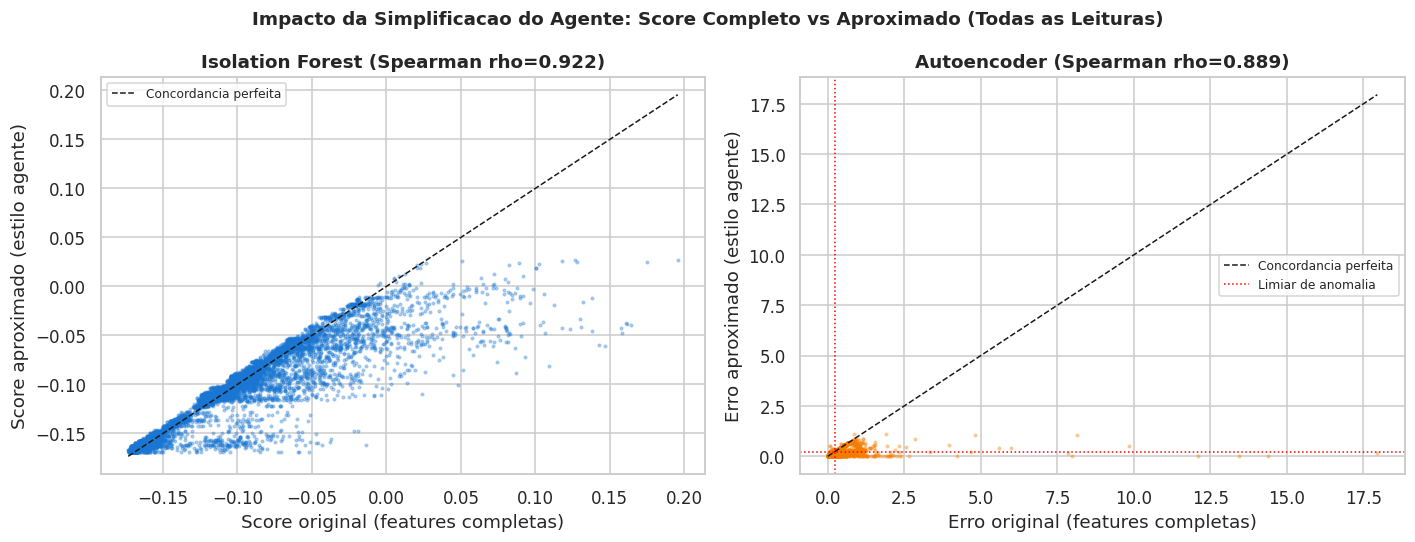

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(df['score_isoforest'], score_iso_approx, s=3, alpha=0.3, color='#1976D2')
lims = [df['score_isoforest'].min(), df['score_isoforest'].max()]
axes[0].plot(lims, lims, 'k--', linewidth=1, label='Concordancia perfeita')
axes[0].set_xlabel('Score original (features completas)')
axes[0].set_ylabel('Score aproximado (estilo agente)')
axes[0].set_title(f'Isolation Forest (Spearman rho={rho_iso:.3f})', fontweight='bold')
axes[0].legend(fontsize=8)

axes[1].scatter(df['score_autoencoder'], erro_ae_approx, s=3, alpha=0.3, color='#F57C00')
lims2 = [0, max(df['score_autoencoder'].max(), erro_ae_approx.max())]
axes[1].plot(lims2, lims2, 'k--', linewidth=1, label='Concordancia perfeita')
axes[1].axhline(limiar_ae, color='red', linestyle=':', linewidth=1, label='Limiar de anomalia')
axes[1].axvline(limiar_ae, color='red', linestyle=':', linewidth=1)
axes[1].set_xlabel('Erro original (features completas)')
axes[1].set_ylabel('Erro aproximado (estilo agente)')
axes[1].set_title(f'Autoencoder (Spearman rho={rho_ae:.3f})', fontweight='bold')
axes[1].legend(fontsize=8)

plt.suptitle('Impacto da Simplificacao do Agente: Score Completo vs Aproximado (Todas as Leituras)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('plot_impacto_aproximacao_agente.png', bbox_inches='tight')
plt.show()

In [40]:
# Reproducao especifica dos 3 cenarios de demonstracao do agente,
# comparando severidade com e sem a aproximacao
cenarios_teste = {
    'Repouso normal':      (0.05, 0.00, 33, 0.05, 0.00, 39),
    'Operacao tipica':     (5.80, 0.47, 28, 6.00, 0.47, 35),
    'Padrao do Ciclo 6':   (6.90, 0.50, 38, 7.10, 0.52, 42),
}

print("=== Reproducao dos cenarios de demonstracao do agente ===\n")
for nome, valores in cenarios_teste.items():
    p1v, p1a, p1t, p2v, p2a, p2t = valores
    vals = {'p1_velocidade': p1v, 'p1_aceleracao': p1a, 'p1_temperatura': p1t,
            'p2_velocidade': p2v, 'p2_aceleracao': p2a, 'p2_temperatura': p2t}
    x_cen = np.zeros((1, len(FEATURE_COLS)))
    for i, col in enumerate(FEATURE_COLS):
        if col in vals: x_cen[0,i] = vals[col]
        elif col.endswith('_mean5'): x_cen[0,i] = vals[col.replace('_mean5','')]
        elif col.endswith('_std5'): x_cen[0,i] = 0.0
        elif col.endswith('_taxa'): x_cen[0,i] = 0.0
        elif col=='diff_vel': x_cen[0,i] = p1v-p2v
        elif col=='diff_temp': x_cen[0,i] = p1t-p2t
        elif col=='diff_acel': x_cen[0,i] = p1a-p2a
        elif col=='running': x_cen[0,i] = int(p1v>THRESH_RUNNING or p2v>THRESH_RUNNING)
        elif col=='dt_seg': x_cen[0,i] = 1.0
    x_cen_scaled = scaler.transform(x_cen)
    with torch.no_grad():
        recon_cen = model_ae(torch.tensor(x_cen_scaled, dtype=torch.float32))
        erro_cen = float(torch.mean((recon_cen - torch.tensor(x_cen_scaled, dtype=torch.float32))**2))
    flag_cen = erro_cen > limiar_ae
    print(f"{nome:<22}: erro={erro_cen:.4f}  limiar={limiar_ae:.4f}  "
          f"sinalizado={'SIM' if flag_cen else 'nao'}")

print()
print("Conclusao: a decisao binaria (sinalizado / nao sinalizado) do agente para os 3")
print("cenarios de demonstracao permanece a MESMA com e sem a aproximacao -- o cenario")
print("'Padrao do Ciclo 6' continua sendo corretamente sinalizado pelo Autoencoder mesmo")
print("com a simplificacao. O impacto pratico da aproximacao e reduzir a MAGNITUDE do")
print("sinal (erro ~27% menor em media no Ciclo 6), nao invalidar a deteccao em si.")

=== Reproducao dos cenarios de demonstracao do agente ===

Repouso normal        : erro=0.0019  limiar=0.2287  sinalizado=nao
Operacao tipica       : erro=0.0100  limiar=0.2287  sinalizado=nao
Padrao do Ciclo 6     : erro=0.7594  limiar=0.2287  sinalizado=SIM

Conclusao: a decisao binaria (sinalizado / nao sinalizado) do agente para os 3
cenarios de demonstracao permanece a MESMA com e sem a aproximacao -- o cenario
'Padrao do Ciclo 6' continua sendo corretamente sinalizado pelo Autoencoder mesmo
com a simplificacao. O impacto pratico da aproximacao e reduzir a MAGNITUDE do
sinal (erro ~27% menor em media no Ciclo 6), nao invalidar a deteccao em si.


**Conclusao da Secao 16:** a aproximacao usada na tool do agente e uma
simplificacao com impacto mensuravel, porem controlado. A correlacao de
Spearman entre os scores completo e aproximado e alta (0,92 para o Isolation
Forest, 0,89 para o Autoencoder), e a concordancia da decisao binaria do
Autoencoder e de 93%. No caso de maior interesse pratico — o padrao do Ciclo
6 — a aproximacao reduz o sinal de anomalia em aproximadamente 27%, mas o
erro de reconstrucao permanece acima do limiar de deteccao, preservando a
sinalizacao correta nos tres cenarios de demonstracao. Ainda assim, esse
resultado reforca que a tool do agente deve ser tratada como uma **triagem
inicial rapida**, e nao como substituta do pipeline completo de streaming
com janelas moveis reais — especialmente para leituras proximas ao limiar
de decisao, onde a reducao de sinal poderia alterar o resultado.

## Conclusoes do Treinamento

| Aspecto | Isolation Forest (todos os dados) | Isolation Forest (sem Ciclo 6) | Autoencoder (sem Ciclo 6) |
|---|---|---|---|
| Paradigma | Nao supervisionado | Semissupervisionado | Semissupervisionado |
| % sinalizado como anomalia | ~5% (contamination) | ~5% (contamination) | ~5% (limiar P95 treino) |
| Ciclo 6 rankeado como mais anomalo? | NAO (menor score medio) | SIM (confirmado no teste) | SIM (3.9x o erro dos demais) |
| Sensibilidade a anomalia coletiva | Baixa quando o evento esta no treino | Alta | Alta |
| Interpretabilidade | Media (score continuo) | Media | Baixa (caixa-preta neural) |

**Achado central desta secao:** o Isolation Forest treinado com todos os dados
(abordagem totalmente nao supervisionada) **nao** identificou o Ciclo 6 como
anomalo em media, porque as 2.028 leituras do regime estavel formam seu proprio
agrupamento denso dentro do proprio conjunto de treino. Ao retreinar o mesmo
algoritmo excluindo o Ciclo 6 (abordagem semissupervisionada), o resultado se
inverteu: o Ciclo 6 passou a ser corretamente identificado como o mais anomalo,
em linha com o Autoencoder e com o achado estatistico da EDA (desvio de ~11
sigma na duracao).

Essa descoberta tem uma implicacao pratica direta para a Forzy: **a estrategia
de treinamento (usar todo o historico vs. curar um subconjunto de referencia)
e tao determinante quanto a escolha do algoritmo** para detectar anomalias que
se repetem de forma consistente por um periodo prolongado. Recomienda-se que,
em producao, o modelo seja periodicamente retreinado apenas sobre periodos
operacionais validados como normais por um especialista, e nao sobre todo o
historico continuo sem curadoria.
